# A10: Pre-release Profitability Screen
**Analyst:** Matt Sorensen | **Course:** EMBA 560 | **Due:** Dec 4, 2026

**Decision (from the frozen Purpose Contract, `report/A10_purpose_contract_FROZEN_2026-11-17.md`):** at the financing stage, a co-financier's Head of Acquisitions sends the 20% of projects with the highest predicted risk of being a money-loser (worldwide revenue < 2.5 × budget) to deep review. Path: predictive. Focal factor: director track record built from earlier films only.

**How to run (VS Code):** select the Python 3.14 kernel (top right), click **Restart** in the notebook toolbar, then **Run All**, then save. Raw files in `../data/raw/` are read only and never written. Prepared files go to `../data/clean/`.

| Section | CRISP-DM phase | Plan step |
|---|---|---|
| 1. Setup | — | — |
| 2. Data Receipt and physical checks | Data Understanding | 8 |
| 3. Univariate profile of every field | Data Understanding | 9 |
| 4. Build and verify the TMDB-RT join | Data Understanding | 10 |

## 1. Setup

In [32]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

RAW = Path("../data/raw")
CLEAN = Path("../data/clean")
FILES = {
    "tmdb":       RAW / "TMDB_movie_dataset_v11.csv",
    "rt_movies":  RAW / "rotten_tomatoes_movies.csv",
    "rt_reviews": RAW / "rotten_tomatoes_movie_reviews.csv",
}
ACCESS_DATE = "2026-11-17"
for name, path in FILES.items():
    assert path.exists(), f"Missing raw file: {path}"
print("All raw files found.")

All raw files found.


## 2. Data Receipt (plan step 8)

The receipt records where each file came from, what we're allowed to do with it, and what one row means. The physical checks below verify the grain and coverage claims instead of trusting the Kaggle pages.

| Field | TMDB | RT movies | RT reviews |
|---|---|---|---|
| **File** | `TMDB_movie_dataset_v11.csv` | `rotten_tomatoes_movies.csv` | `rotten_tomatoes_movie_reviews.csv` |
| **Publisher (Kaggle uploader)** | asaniczka | andrezaza | andrezaza |
| **Original source** | The Movie Database (TMDB), a crowd-edited film database | Rotten Tomatoes website | Rotten Tomatoes website |
| **URL** | kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies | kaggle.com/datasets/andrezaza/clapper-massive-rotten-tomatoes-movies-and-reviews | same as RT movies |
| **Access date** | 2026-11-17 | 2026-11-17 | 2026-11-17 |
| **License (as stated by uploader)** | ODC Attribution 1.0: credit required | CC0 1.0 (public domain) | CC0 1.0 (public domain) |
| **Collection** | Compiled by the uploader from TMDB. Values are entered by TMDB's volunteer editors, not audited financials. | Compiled by the uploader from RT pages | Compiled by the uploader from RT pages |
| **Claimed grain** | One row per TMDB movie id | One row per RT movie (URL slug) | One row per critic review |
| **Population** | Every title listed on TMDB, including unreleased, adult and very obscure titles | Every title listed on RT | Reviews collected on RT |
| **Sensitive fields** | None about private individuals. `adult` flags adult titles, which are excluded from analysis. | `director`, `writer`: names of public professionals | `criticName`, `reviewText`, `reviewUrl`: named people and their copyrighted writing |
| **Rights caveats** | The uploader's license can't override TMDB's own API terms of use. | Critic and audience scores belong to RT. | Review text is copyrighted by critics and publications whatever the CC0 label says. |
| **Permitted use here** | Academic, non-commercial analysis. Cite the source. | Same | Same. Quote review text only in short excerpts. Results never rank named people (contract prohibited use #1). |

### 2a. File fingerprints
The SHA-256 hash proves the raw files are unchanged at submission: rerun this cell later, and the hashes must match the values recorded here.

In [33]:
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

fingerprints = pd.DataFrame(
    [{"file": p.name, "MB": round(p.stat().st_size / 1e6, 1), "sha256": sha256(p)} for p in FILES.values()]
)
fingerprints

,file,MB,sha256
0,TMDB_movie_dataset_v11.csv,677.0,0e59237db87590d3118765060ba611b2310c736cff4f42...
1,rotten_tomatoes_movies.csv,17.4,7a2e0e33d77def8b5da502227d9465a07c4131055c5a4c...
2,rotten_tomatoes_movie_reviews.csv,410.7,fce65e53761e807276a16a2f1409da1314845003651832...


### 2b. Load the raw files (read only)

In [34]:
tmdb = pd.read_csv(FILES["tmdb"], low_memory=False)
rt_movies = pd.read_csv(FILES["rt_movies"], low_memory=False)
rt_reviews = pd.read_csv(FILES["rt_reviews"], low_memory=False)
for name, df in [("tmdb", tmdb), ("rt_movies", rt_movies), ("rt_reviews", rt_reviews)]:
    print(f"{name:11s} {df.shape[0]:>10,} rows x {df.shape[1]} columns")

tmdb         1,538,765 rows x 24 columns
rt_movies      143,258 rows x 16 columns
rt_reviews   1,444,963 rows x 11 columns


### 2c. Grain check
Does one row really equal one movie (or one review)? Duplicate keys break joins and double-count films.

In [35]:
def grain_check(df, key):
    return {
        "rows": len(df),
        "key": key,
        "unique keys": df[key].nunique(),
        "rows with a repeated key": int(df[key].duplicated(keep=False).sum()),
        "exact duplicate rows": int(df.duplicated().sum()),
    }

grain = pd.DataFrame({
    "tmdb": grain_check(tmdb, "id"),
    "rt_movies": grain_check(rt_movies, "id"),
    "rt_reviews": grain_check(rt_reviews, "reviewId"),
})
grain

,tmdb,rt_movies,rt_reviews
rows,1538765,143258,1444963
key,id,id,reviewId
unique keys,1537358,142052,1432569
rows with a repeated key,2467,2412,24788
exact duplicate rows,385,1204,12394


In [36]:
# Are repeated keys identical copies, or conflicting records?
for name, df, key in [("tmdb", tmdb, "id"), ("rt_movies", rt_movies, "id")]:
    rep = df[df[key].duplicated(keep=False)]
    n_versions = rep.drop_duplicates().groupby(key).size()
    print(f"{name}: {rep[key].nunique():,} repeated keys; "
          f"{(n_versions > 1).sum():,} of them have conflicting values across copies")

tmdb: 1,060 repeated keys; 1,019 of them have conflicting values across copies
rt_movies: 1,206 repeated keys; 2 of them have conflicting values across copies


### 2d. Missing coverage by column

In [37]:
def missing_table(df):
    return (df.isna().mean() * 100).round(1).rename("% missing").to_frame()

with pd.option_context("display.max_rows", 60):
    display(missing_table(tmdb).T)
    display(missing_table(rt_movies).T)
    display(missing_table(rt_reviews).T)

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,budget,homepage,imdb_id,original_language,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
% missing,0.0,0.0,0.0,0.0,0.0,24.4,0.0,0.0,0.0,75.8,0.0,89.8,54.7,0.0,0.0,23.6,0.0,37.0,86.0,45.3,58.4,50.0,48.0,75.9


,id,title,audienceScore,tomatoMeter,rating,ratingContents,releaseDateTheaters,releaseDateStreaming,runtimeMinutes,genre,originalLanguage,director,writer,boxOffice,distributor,soundMix
% missing,0.0,0.3,48.9,76.4,90.2,90.2,78.5,44.6,9.7,7.7,9.7,2.9,37.1,89.7,83.9,88.9


,id,reviewId,creationDate,criticName,isTopCritic,originalScore,reviewState,publicatioName,reviewText,scoreSentiment,reviewUrl
% missing,0.0,0.0,0.0,0.0,0.0,30.1,0.0,0.0,4.8,0.0,14.6


TMDB uses **0, not blank,** for an unknown budget or revenue, so the table above understates how much of that is missing. The next cell counts zeros as missing.

In [38]:
for col in ["budget", "revenue", "runtime"]:
    zero_share = (tmdb[col] == 0).mean() * 100
    print(f"TMDB {col}: {zero_share:.1f}% of rows are 0 (unknown)")

TMDB budget: 94.1% of rows are 0 (unknown)
TMDB revenue: 98.3% of rows are 0 (unknown)
TMDB runtime: 32.1% of rows are 0 (unknown)


### 2e. Date coverage and placeholder dates

In [39]:
dates = {
    "TMDB release_date": pd.to_datetime(tmdb["release_date"], errors="coerce"),
    "RT releaseDateTheaters": pd.to_datetime(rt_movies["releaseDateTheaters"], errors="coerce"),
    "RT releaseDateStreaming": pd.to_datetime(rt_movies["releaseDateStreaming"], errors="coerce"),
    "RT review creationDate": pd.to_datetime(rt_reviews["creationDate"], errors="coerce"),
}
pd.DataFrame({
    name: {
        "min": d.min().date(), "max": d.max().date(),
        "% missing": round(d.isna().mean() * 100, 1),
        "before 1900 (placeholder?)": int((d.dt.year < 1900).sum()),
        f"after access date {ACCESS_DATE}": int((d > ACCESS_DATE).sum()),
    } for name, d in dates.items()
}).T

,min,max,% missing,before 1900 (placeholder?),after access date 2026-11-17
TMDB release_date,1800-01-01,2099-12-31,24.4,2217,1740
RT releaseDateTheaters,1902-10-04,2032-04-21,78.5,0,3
RT releaseDateStreaming,1928-12-18,2023-12-22,44.6,0,0
RT review creationDate,1800-01-01,2023-04-08,0.0,71,0


### 2f. Coverage of the contract population
The frozen contract's population: feature films released 2000–2023, budget ≥ $1M, worldwide revenue > 0, not adult. This cell counts how many films qualify and how many drop out **only because revenue is missing**, which is the first half of stop condition S4. It counts records; it doesn't look at how any input relates to the outcome.

In [40]:
t = tmdb.drop_duplicates("id").copy()
t["year"] = pd.to_datetime(t["release_date"], errors="coerce").dt.year

steps = [
    ("all unique TMDB ids", pd.Series(True, index=t.index)),
    ("status == Released", t["status"].eq("Released")),
    ("not adult", ~t["adult"]),
    ("released 2000-2023", t["year"].between(2000, 2023)),
    ("budget >= $1M", t["budget"].ge(1_000_000)),
    ("revenue > 0", t["revenue"].gt(0)),
]
mask = pd.Series(True, index=t.index)
funnel = []
for label, cond in steps:
    mask &= cond
    funnel.append({"filter (cumulative)": label, "films remaining": int(mask.sum())})
funnel = pd.DataFrame(funnel)
display(funnel)

pre_revenue = funnel.iloc[-2]["films remaining"]
final = funnel.iloc[-1]["films remaining"]
print(f"Films with budget >= $1M but no revenue recorded: {pre_revenue - final:,} "
      f"({(pre_revenue - final) / pre_revenue:.1%} of the budget-qualified films)")

,filter (cumulative),films remaining
0,all unique TMDB ids,1537358
1,status == Released,1475782
2,not adult,1325026
3,released 2000-2023,585312
4,budget >= $1M,10221
5,revenue > 0,5766


Films with budget >= $1M but no revenue recorded: 4,455 (43.6% of the budget-qualified films)


In [41]:
# Budgets that are almost certainly entry errors (e.g., '5' meaning $5M)
released = t[t["status"].eq("Released") & (t["budget"] > 0)]
for lo, hi in [(1, 999), (1_000, 99_999), (100_000, 999_999)]:
    n = released["budget"].between(lo, hi).sum()
    print(f"budget ${lo:,} to ${hi:,}: {n:,} released films")

budget $1 to $999: 34,106 released films
budget $1,000 to $99,999: 28,368 released films
budget $100,000 to $999,999: 6,936 released films


In [42]:
# Same funnel, split by the contract's train / test / stress periods
base = t["status"].eq("Released") & ~t["adult"] & t["budget"].ge(1_000_000)
rows = []
for label, lo, hi in [("train", 2000, 2015), ("test", 2016, 2019), ("stress", 2020, 2023)]:
    qualified = base & t["year"].between(lo, hi)
    with_rev = qualified & t["revenue"].gt(0)
    rows.append({"period": f"{label} {lo}-{hi}", "budget >= $1M": int(qualified.sum()),
                 "with revenue": int(with_rev.sum()),
                 "% missing revenue": round(100 * (1 - with_rev.sum() / qualified.sum()), 1)})
pd.DataFrame(rows)

,period,budget >= $1M,with revenue,% missing revenue
0,train 2000-2015,7112,4145,41.7
1,test 2016-2019,1895,1086,42.7
2,stress 2020-2023,1214,535,55.9


### 2g. Receipt findings and fitness disposition

**What the checks showed**
1. **Fingerprints recorded.** The three SHA-256 hashes in 2a are the reference for "raw data preserved."
2. **The grain is not clean in any file.**
   - TMDB: 1,060 ids appear more than once, and 1,019 of them have *conflicting* values across copies. Phase 3 needs an explicit rule for which copy to keep.
   - RT movies: 1,206 repeated slugs, almost all exact copies.
   - RT reviews: 24,788 rows share a reviewId, and 12,394 are exact duplicates.
3. **TMDB stores unknown values as 0, not blank.** Budget is unknown for 94.1% of all titles and revenue for 98.3%. The column-level missing table makes the data look complete, and it isn't.
4. **There are placeholder and future dates.** 1800-01-01 appears as a placeholder (2,217 TMDB titles, 71 RT reviews). 1,740 TMDB titles carry dates after the access date, meaning unreleased films. The population filter removes both.
5. **Budget entry errors.** 34,106 released films list a budget of $1–$999, which is almost certainly typed in millions or just junk. The $1M floor drops them, and that's an information loss to log in Phase 3.
6. **Population size (frozen contract):** 5,766 films. That's 4,145 for training (2000–2015), 1,086 for testing (2016–2019) and 535 for the stress test (2020–2023).

**Material risk: missing revenue (stop condition S4)**
43.6% of films with a budget of at least $1M have **no revenue recorded** (41.7% train, 42.7% test, 55.9% stress). If those films are mostly flops that nobody bothered to report, the population is short on exactly the money-losers the screen exists to catch, and both the base rate and capture will be biased. That's checked in step 10, using RT domestic box office for the films that join.

**Fitness disposition: FIT WITH CONDITIONS.** The sources support the contract's decision, unit and time order. The financial fields are volunteer-entered and need cleaning rules (duplicates, zeros, unit errors). The disposition becomes final only after the S4 check: if the films missing revenue turn out to skew toward losers, the claim is restricted to films with reported revenue, or the project redirects.

## 3. Univariate profile of every field (plan step 9)

**Goal:** describe all 51 supplied fields, plus the derived measures, one field at a time, so the readiness gate (step 12) and the cleaning ledger (step 13) start from evidence. This section **observes and records; it doesn't clean.** Nothing is written to disk.

**Which rows (decided by Matt, 2026-11-18):**
- **TMDB:** the 5,766 films in the contract population (2f), so the numbers describe the films the screen will score. Raw-file problems (duplicate ids, zeros for unknowns, placeholder dates) are already in §2.
- **The label** (revenue ÷ budget and the money-loser flag) is shown separately for train, test and stress, so any drift is visible. This is description only: nothing here is tuned on the test years.
- **RT movies and RT reviews:** whole files. The RT films that join to the population get profiled again after the join is built (step 10).

**Review flags (Ch 6):** |skew| > 0.5, and any category level held by fewer than 5% of non-missing rows. A flag means "look at this," not "fix this automatically."

**Privacy (contract prohibited use #1):** director, writer and critic names are profiled by counts only. No named person is listed or ranked.

| Part | Contents |
|---|---|
| 3a | Field inventory: type and role at the financing decision for all 51 fields |
| 3b | The label first |
| 3c–3f | TMDB numeric, categorical, identifier/text and date fields |
| 3g | RT movies (16 fields) |
| 3h | RT reviews (11 fields) |
| 3i | Flag register (hand-off to steps 12–13) |

In [43]:
import matplotlib.pyplot as plt

# Chart style: one hue per series, fixed colour per period, recessive grid
SERIES = {"train 2000-15": "#2a78d6", "test 2016-19": "#eb6834", "stress 2020-23": "#1baf7a"}
BLUE, BLUE_LIGHT, INK, INK2 = "#2a78d6", "#cde2fb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.titlesize": 10, "axes.titlelocation": "left", "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
})

SKEW_FLAG, RARE_FLAG = 0.5, 0.05   # Ch 6 review flags
FLAGS = []                         # checks that need a human look; collected into the 3i register

def flag(file, field, issue, evidence):
    FLAGS.append({"file": file, "field": field, "issue": issue, "evidence": evidence})


def numeric_profile(df, cols, zero_as_missing=()):
    # Center, spread and shape for each numeric column (Ch 6, Table 6.1)
    rows = []
    for c in cols:
        s = df[c].astype(float)
        if c in zero_as_missing:
            s = s.mask(s == 0)
        x = s.dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        rows.append({
            "field": c, "n": len(x), "% missing": round(100 * s.isna().mean(), 1),
            "mean": x.mean(), "median": x.median(), "std": x.std(),
            "min": x.min(), "Q1": q1, "Q3": q3, "max": x.max(), "IQR": iqr, "skew": x.skew(),
            "# above Q3+1.5 IQR": int((x > q3 + 1.5 * iqr).sum()),
            "# below Q1-1.5 IQR": int((x < q1 - 1.5 * iqr).sum()),
        })
    out = pd.DataFrame(rows).set_index("field")
    out["skew flag"] = out["skew"].abs() > SKEW_FLAG
    return out


def category_profile(s, name, multi=False, names_hidden=False):
    # Levels, top level, and rare levels for a category; multi-label fields are split on commas
    n = s.notna().sum()
    vals = s.dropna().astype(str)
    if multi:
        vals = vals.str.split(",").explode().str.strip()
    vc = vals.value_counts()
    share = vc / n                                  # share of non-missing rows carrying each level
    row = {
        "field": name, "% missing": round(100 * s.isna().mean(), 1), "multi-label": multi,
        "levels": len(vc),
        "top level": "(person, withheld)" if names_hidden else vc.index[0],
        "top level % of rows": round(100 * share.iloc[0], 1),
        "levels < 5% of rows": int((share < RARE_FLAG).sum()),
        "% of rows in a level < 5%": None if multi else round(100 * share[share < RARE_FLAG].sum(), 1),
    }
    return row, vc


def id_text_profile(df, cols):
    # Identifiers and free text get uniqueness, duplicates and length, never averages
    rows = []
    for c in cols:
        s = df[c]
        nn = s.dropna().astype(str)
        rows.append({
            "field": c, "% missing": round(100 * s.isna().mean(), 1),
            "unique values": nn.nunique(),
            "rows sharing a value": int(nn.duplicated(keep=False).sum()),
            "median length (chars)": nn.str.len().median(),
        })
    return pd.DataFrame(rows).set_index("field")


def box_hist(ax_box, ax_hist, x, title, xlabel, ylabel, log=False):
    # Box plot stacked over a histogram (Ch 6), with mean and median lines
    x = x.dropna().astype(float)
    if log and (x <= 0).any():
        title += f"\n({(x <= 0).sum():,} values <= 0 not shown on the log scale)"
        x = x[x > 0]
    bins = int(np.ceil(len(x) ** (1 / 3)))          # cube-root rule
    edges = np.logspace(np.log10(x.min()), np.log10(x.max()), bins + 1) if log else bins
    ax_hist.hist(x, bins=edges, color=BLUE, edgecolor="white", linewidth=0.4)
    ax_box.boxplot(x, orientation="horizontal", widths=0.6, patch_artist=True,
                   boxprops=dict(facecolor=BLUE_LIGHT, edgecolor=BLUE),
                   medianprops=dict(color=INK, linewidth=1.5),
                   whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
                   flierprops=dict(marker="o", markersize=2.5, markerfacecolor=BLUE,
                                   markeredgecolor="none", alpha=0.35))
    ax_hist.axvline(x.median(), color=INK, lw=1, label=f"median {x.median():,.3g}")
    ax_hist.axvline(x.mean(), color=INK, lw=1, ls="--", label=f"mean {x.mean():,.3g}")
    if log:
        ax_hist.set_xscale("log")
    ax_box.set_yticks([])
    ax_box.grid(False)
    ax_box.set_title(title)
    ax_hist.set_xlabel(xlabel)
    ax_hist.set_ylabel(ylabel)
    ax_hist.legend(fontsize=7, frameon=False)


def profile_grid(specs, ylabel, ncols=3):
    # specs: list of (series, title, x-axis label, log scale?)
    nrows = int(np.ceil(len(specs) / ncols))
    fig = plt.figure(figsize=(4.3 * ncols, 3.1 * nrows), layout="constrained")
    subfigs = np.atleast_1d(fig.subfigures(nrows, ncols)).ravel()
    for sf, (x, title, xlabel, log) in zip(subfigs, specs):
        ax_box, ax_hist = sf.subplots(2, 1, sharex=True, height_ratios=[1, 4])
        box_hist(ax_box, ax_hist, x, title, xlabel, ylabel, log)
    plt.show()


def count_plot(ax, vc, n_rows, title, top=10, xlabel="% of rows"):
    # Horizontal bars sorted by frequency; dotted line = the 5% rare-level flag
    shares = (100 * vc / n_rows).head(top)[::-1]
    ax.barh(shares.index.astype(str), shares.values, color=BLUE, height=0.7)
    ax.axvline(100 * RARE_FLAG, color=INK2, ls=":", lw=1)
    for y, v in enumerate(shares.values):
        ax.text(v, y, f" {v:.1f}%", va="center", fontsize=7, color=INK2)
    ax.set_title(title + (f"  (top {top} of {len(vc):,})" if len(vc) > top else ""))
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)

print("Profile helpers defined.")

Profile helpers defined.


In [44]:
# Contract population (same filters as the 2f funnel), one row per TMDB id
pop = t[
    t["status"].eq("Released") & ~t["adult"] & t["year"].between(2000, 2023)
    & t["budget"].ge(1_000_000) & t["revenue"].gt(0)
].copy()
pop["period"] = pd.cut(pop["year"], [1999, 2015, 2019, 2023], labels=list(SERIES))

# Derived measures, computed in memory only
pop["multiple"] = pop["revenue"] / pop["budget"]          # revenue / budget
pop["log10_multiple"] = np.log10(pop["multiple"])
for k in [1, 2, 2.5, 3]:
    pop[f"loser_{k}x"] = pop["multiple"] < k             # 2.5x = contract label; others = sensitivity
pop["money_loser"] = pop["loser_2.5x"]
pop["release_dt"] = pd.to_datetime(pop["release_date"], errors="coerce")
pop["release_month"] = pop["release_dt"].dt.month
pop["n_genres"] = pop["genres"].str.split(",").str.len()

assert len(pop) == 5766 and pop["id"].is_unique, "population doesn't match the 2f funnel"
print(f"Population: {len(pop):,} films")
print(pop["period"].value_counts().sort_index().to_string())

Population: 5,766 films
period
train 2000-15     4145
test 2016-19      1086
stress 2020-23     535


### 3a. Field inventory
Every supplied field, with its type and what the contract lets it do at the financing decision. **Prohibited** fields are known only after release. They're profiled for data quality, but they can never be model inputs.

In [45]:
A, P, K, O, N = ("allowed input", "prohibited (post-release)", "key / join",
                 "outcome part (post-release)", "not used")
inventory = pd.DataFrame([
    # TMDB (24)
    ("TMDB", "id", "identifier", K),
    ("TMDB", "title", "identifier (text)", K + " (title match)"),
    ("TMDB", "vote_average", "numeric", P),
    ("TMDB", "vote_count", "count", P),
    ("TMDB", "status", "category", "population filter"),
    ("TMDB", "release_date", "timestamp", A + " (month, quarter); year sets the split"),
    ("TMDB", "revenue", "numeric (US$)", O),
    ("TMDB", "runtime", "numeric (minutes)", A + " (final, not planned: weak link 4)"),
    ("TMDB", "adult", "flag", "population filter"),
    ("TMDB", "backdrop_path", "URL / path", N),
    ("TMDB", "budget", "numeric (US$)", A + "; also the outcome's denominator"),
    ("TMDB", "homepage", "URL / path", N),
    ("TMDB", "imdb_id", "identifier", K + " (possible)"),
    ("TMDB", "original_language", "category", A),
    ("TMDB", "original_title", "free text", N + " (join fallback)"),
    ("TMDB", "overview", "free text", N),
    ("TMDB", "popularity", "numeric (index)", P),
    ("TMDB", "poster_path", "URL / path", N),
    ("TMDB", "tagline", "free text", N),
    ("TMDB", "genres", "multi-label category", A),
    ("TMDB", "production_companies", "multi-label category", A + " (track record from earlier films)"),
    ("TMDB", "production_countries", "multi-label category", A),
    ("TMDB", "spoken_languages", "multi-label category", N + " (not in the contract's input list)"),
    ("TMDB", "keywords", "multi-label category", P + " (crowd-edited after release)"),
    # RT movies (16)
    ("RT movies", "id", "identifier (URL slug)", K + " (to RT reviews)"),
    ("RT movies", "title", "identifier (text)", K + " (title match)"),
    ("RT movies", "audienceScore", "numeric (0-100)", P),
    ("RT movies", "tomatoMeter", "numeric (0-100)", P),
    ("RT movies", "rating", "category (MPAA)", N + " (not in the contract's input list)"),
    ("RT movies", "ratingContents", "free text (list)", N),
    ("RT movies", "releaseDateTheaters", "timestamp", K + " (year check)"),
    ("RT movies", "releaseDateStreaming", "timestamp", N),
    ("RT movies", "runtimeMinutes", "numeric (minutes)", K + " (tiebreak)"),
    ("RT movies", "genre", "multi-label category", N + " (TMDB genres used)"),
    ("RT movies", "originalLanguage", "category", N + " (TMDB language used)"),
    ("RT movies", "director", "person name (multi)", A + " (track record from earlier films)"),
    ("RT movies", "writer", "person name (multi)", N),
    ("RT movies", "boxOffice", "text-coded US$", O + "; S4 cross-check only"),
    ("RT movies", "distributor", "category", N + " (not in the contract's input list)"),
    ("RT movies", "soundMix", "multi-label category", N),
    # RT reviews (11)
    ("RT reviews", "id", "identifier (foreign key)", K + " (to RT movies)"),
    ("RT reviews", "reviewId", "identifier", K),
    ("RT reviews", "creationDate", "timestamp", P + "; step 11 early-review test"),
    ("RT reviews", "criticName", "person name", N),
    ("RT reviews", "isTopCritic", "flag", P),
    ("RT reviews", "originalScore", "text-coded score", P),
    ("RT reviews", "reviewState", "category", P),
    ("RT reviews", "publicatioName", "category", P),
    ("RT reviews", "reviewText", "free text", P + "; copyrighted"),
    ("RT reviews", "scoreSentiment", "category", P),
    ("RT reviews", "reviewUrl", "URL / path", N),
], columns=["file", "field", "kind", "role at financing decision"])

# Every supplied column is listed exactly once
for file, df in [("TMDB", tmdb), ("RT movies", rt_movies), ("RT reviews", rt_reviews)]:
    listed = inventory.loc[inventory["file"] == file, "field"]
    assert listed.is_unique and set(listed) == set(df.columns), f"{file}: inventory != columns"
print(f"{len(inventory)} fields inventoried (TMDB {tmdb.shape[1]}, RT movies {rt_movies.shape[1]}, "
      f"RT reviews {rt_reviews.shape[1]})")

derived = pd.DataFrame([
    ("multiple", "revenue / budget", "outcome (post-release)"),
    ("money_loser (loser_2.5x)", "multiple < 2.5", "the contract label"),
    ("loser_1x, loser_2x, loser_3x", "multiple < 1, 2, 3", "label sensitivity"),
    ("release_month", "month of release_date", A),
    ("n_genres", "number of TMDB genres", A),
], columns=["derived measure", "definition", "role"])

with pd.option_context("display.max_rows", 60, "display.max_colwidth", 70):
    display(inventory)
    display(derived)
inventory["role at financing decision"].str.split(r" \(|;").str[0].value_counts()

51 fields inventoried (TMDB 24, RT movies 16, RT reviews 11)


,file,field,kind,role at financing decision
0,TMDB,id,identifier,key / join
1,TMDB,title,identifier (text),key / join (title match)
2,TMDB,vote_average,numeric,prohibited (post-release)
3,TMDB,vote_count,count,prohibited (post-release)
4,TMDB,status,category,population filter
5,TMDB,release_date,timestamp,"allowed input (month, quarter); year sets the split"
6,TMDB,revenue,numeric (US$),outcome part (post-release)
7,TMDB,runtime,numeric (minutes),"allowed input (final, not planned: weak link 4)"
8,TMDB,adult,flag,population filter
9,TMDB,backdrop_path,URL / path,not used


,derived measure,definition,role
0,multiple,revenue / budget,outcome (post-release)
1,money_loser (loser_2.5x),multiple < 2.5,the contract label
2,"loser_1x, loser_2x, loser_3x","multiple < 1, 2, 3",label sensitivity
3,release_month,month of release_date,allowed input
4,n_genres,number of TMDB genres,allowed input


role at financing decision
not used             17
prohibited           13
key / join            9
allowed input         8
population filter     2
outcome part          2
Name: count, dtype: int64

### 3b. The label first: revenue ÷ budget and the money-loser flag
The contract label is **money-loser = revenue < 2.5 × budget**, rerun at 1×, 2× and 3× as a sensitivity check. The multiple is a ratio of two money amounts, so it's expected to be strongly right-skewed. The log scale shows its shape.

,films,median multiple,Q1,Q3,skew (multiple),skew (log10 multiple),% losers at 1x,% losers at 2x,% losers at 2.5x,% losers at 3x
train 2000-15,4145.0,1.60,0.53,3.30,8.69,-2.17,36.91,57.01,65.24,71.89
test 2016-19,1086.0,1.84,0.65,4.00,29.99,-1.53,33.79,52.49,59.76,65.38
stress 2020-23,535.0,1.13,0.41,3.03,20.18,-3.03,45.23,62.80,69.53,74.21
all 2000-23,5766.0,1.59,0.53,3.41,48.76,-2.27,37.10,56.69,64.60,70.88


,films
multiple < 0.01 (revenue under 1% of budget),179
multiple < 0.1,579
multiple > 20,81
multiple > 100,5


Lowest 5 multiples:


,title,year,budget,revenue,multiple
1318045,Aquajots,2012.0,100000000,1,1.000000e-08
430151,Diggy and The Bandits,2001.0,447000000,12,2.684564e-08
432213,Diggy and The Bandits,2001.0,447000000,12,2.684564e-08
1336997,The Jerma Show,2022.0,60000000,2,3.333333e-08
1254644,How the Stephen Stole Christmas (ORIGINAL VIDEO),2009.0,100000000,10,1.000000e-07


Highest 5 multiples:


,title,year,budget,revenue,multiple
284874,Vacancy,2018.0,1000000,903400045,903.400045
431700,Lyna Live From Buenos Aires: Gran Rex,2023.0,1000000,400000000,400.000000
1653,Dragon Ball Super: Broly,2018.0,1000000,125002821,125.002821
4969,The Devil Inside,2012.0,1000000,101758490,101.758490
287300,The Book of Mormon,2011.0,9000000,905000000,100.555556


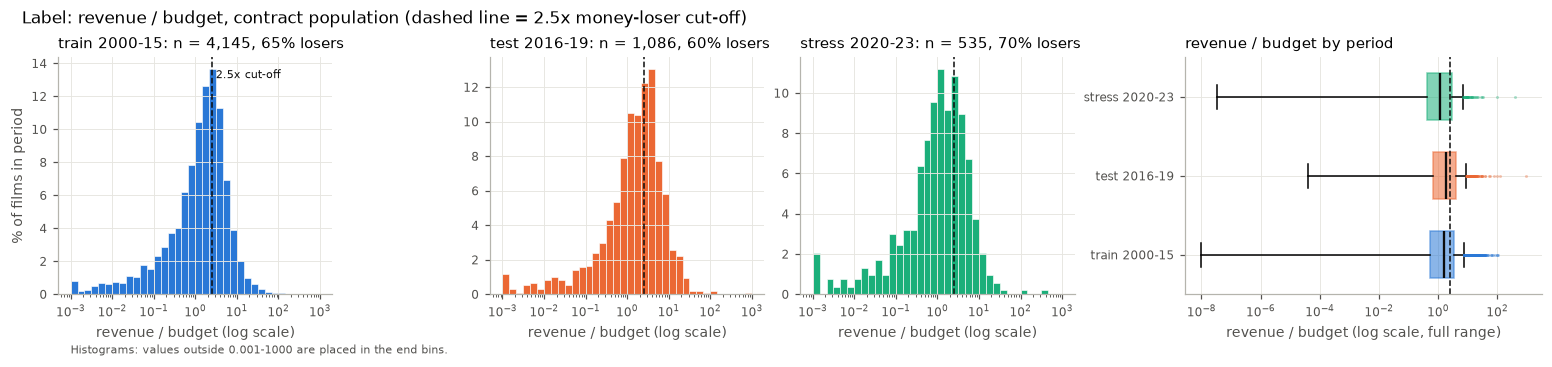

In [46]:
def label_summary(g):
    return pd.Series({
        "films": len(g),
        "median multiple": g["multiple"].median(),
        "Q1": g["multiple"].quantile(0.25), "Q3": g["multiple"].quantile(0.75),
        "skew (multiple)": g["multiple"].skew(), "skew (log10 multiple)": g["log10_multiple"].skew(),
        **{f"% losers at {k}x": 100 * g[f"loser_{k}x"].mean() for k in [1, 2, 2.5, 3]},
    })

label_tbl = pd.DataFrame(
    {p: label_summary(g) for p, g in pop.groupby("period", observed=True)}
    | {"all 2000-23": label_summary(pop)}
).T
display(label_tbl.round(2))

# Extreme multiples: values this far out usually mean a units error in budget or revenue
extremes = pd.Series({
    "multiple < 0.01 (revenue under 1% of budget)": (pop["multiple"] < 0.01).sum(),
    "multiple < 0.1": (pop["multiple"] < 0.1).sum(),
    "multiple > 20": (pop["multiple"] > 20).sum(),
    "multiple > 100": (pop["multiple"] > 100).sum(),
}, name="films")
display(extremes.to_frame())
cols = ["title", "year", "budget", "revenue", "multiple"]
print("Lowest 5 multiples:")
display(pop.nsmallest(5, "multiple")[cols])
print("Highest 5 multiples:")
display(pop.nlargest(5, "multiple")[cols])
flag("TMDB (population)", "multiple", "extreme values",
     f"{extremes.iloc[0]} films below 0.01x and {extremes.iloc[3]} above 100x: check for unit errors")
flag("TMDB (population)", "money_loser", "majority class",
     f"{label_tbl.loc['all 2000-23', '% losers at 2.5x']:.1f}% of films are losers at 2.5x, so a 20% flag "
     f"can catch at most {20 / label_tbl.loc['all 2000-23', '% losers at 2.5x']:.0%} of them")

# Shape by period: histograms (share of films) on a common log scale, then box plots
edges = np.logspace(-3, 3, 37)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), width_ratios=[1, 1, 1, 1.3], layout="constrained")
for ax, (p, g) in zip(axes[:3], pop.groupby("period", observed=True)):
    x = g["multiple"].clip(edges[0], edges[-1])
    ax.hist(x, bins=edges, weights=np.full(len(x), 100 / len(x)), color=SERIES[p],
            edgecolor="white", linewidth=0.4)
    ax.axvline(2.5, color=INK, lw=1, ls="--")
    ax.set_xscale("log")
    ax.set_title(f"{p}: n = {len(g):,}, {100 * g['money_loser'].mean():.0f}% losers")
    ax.set_xlabel("revenue / budget (log scale)")
axes[0].set_ylabel("% of films in period")
axes[0].text(2.5, axes[0].get_ylim()[1] * 0.95, " 2.5x cut-off", fontsize=7, color=INK, va="top")
groups = [g["multiple"] for _, g in pop.groupby("period", observed=True)]
bp = axes[3].boxplot(groups, orientation="horizontal", patch_artist=True, widths=0.6,
                     medianprops=dict(color=INK, linewidth=1.5),
                     flierprops=dict(marker="o", markersize=2, markeredgecolor="none", alpha=0.35))
for patch, flier, p in zip(bp["boxes"], bp["fliers"], SERIES):
    patch.set(facecolor=SERIES[p], alpha=0.55, edgecolor=SERIES[p])
    flier.set_markerfacecolor(SERIES[p])
axes[3].set_yticks([1, 2, 3], list(SERIES))
axes[3].set_xscale("log")
axes[3].axvline(2.5, color=INK, lw=1, ls="--")
axes[3].set_title("revenue / budget by period")
axes[3].set_xlabel("revenue / budget (log scale, full range)")
axes[0].text(0.001, -0.25, "Histograms: values outside 0.001-1000 are placed in the end bins.",
             transform=axes[0].get_xaxis_transform(), fontsize=7, color=INK2)
fig.suptitle("Label: revenue / budget, contract population (dashed line = 2.5x money-loser cut-off)",
             x=0.01, ha="left", fontsize=11)
plt.show()

### 3c. TMDB numeric fields (contract population)
`runtime` uses 0 for unknown, so 0 is counted as missing. `vote_average`, `vote_count` and `popularity` are post-release: they're profiled for quality only. Money and count fields are shown on log scales.

,n,% missing,mean,median,std,min,Q1,Q3,max,IQR,skew,# above Q3+1.5 IQR,# below Q1-1.5 IQR,skew flag
field,,,,,,,,,,,,,,
budget,5766,0.00,"34,225,434.27","16,000,000.00","49,870,136.85","1,000,000.00","5,500,000.00","40,000,000.00","874,362,803.00","34,500,000.00",4.15,552,0,True
revenue,5766,0.00,"96,661,036.71","23,540,415.50","210,329,829.14",1.00,"4,500,000.00","92,326,399.00","3,800,000,000.00","87,826,399.00",5.71,639,0,True
runtime,5714,0.90,111.92,106.00,41.20,1.00,95.00,122.00,999.00,27.00,13.72,167,36,True
vote_average,5766,0.00,6.24,6.39,1.32,0.00,5.80,6.97,10.00,1.17,-2.29,37,218,True
vote_count,5766,0.00,"2,018.39",698.50,"3,423.13",0.00,140.00,"2,273.75","34,495.00","2,133.75",3.39,604,0,True
popularity,5766,0.00,24.10,14.51,80.08,0.00,8.60,23.35,"2,994.36",14.75,22.69,450,0,True
multiple,5766,0.00,3.19,1.59,14.19,0.00,0.53,3.41,903.40,2.88,48.76,408,0,True
log10_multiple,5766,0.00,0.02,0.20,0.86,-8.00,-0.28,0.53,2.96,0.81,-2.27,15,332,True
n_genres,5736,0.50,2.59,3.00,1.06,1.00,2.00,3.00,7.00,1.00,0.47,247,0,False


,films
runtime = 0 (unknown),52
runtime < 60 min (short for a feature),36
runtime > 240 min,20
budget > $400M,7
vote_count = 0,125
vote_average = 0,125
budget is a round $1M multiple,4330
"revenue < $1,000 (typed in millions, or junk)",24
"revenue < $100,000",244


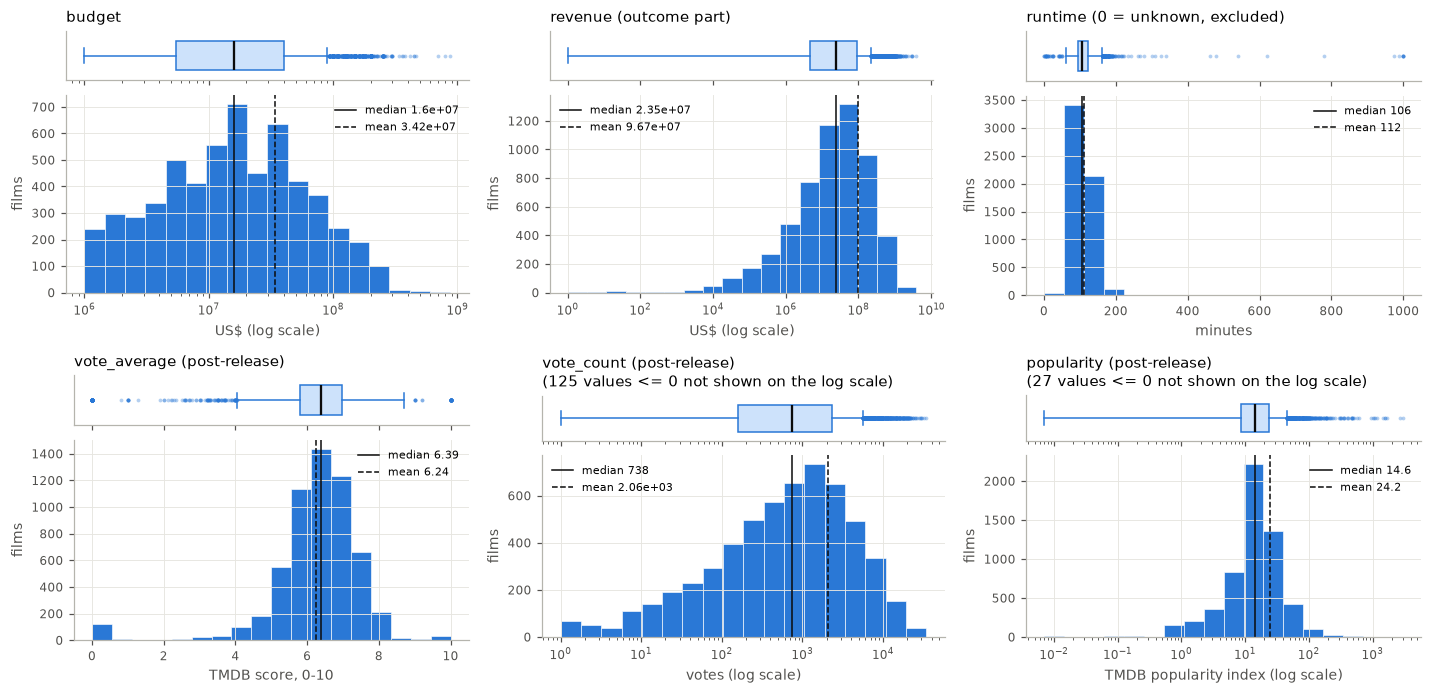

In [47]:
tmdb_num = ["budget", "revenue", "runtime", "vote_average", "vote_count", "popularity",
            "multiple", "log10_multiple", "n_genres"]
prof_tmdb_num = numeric_profile(pop, tmdb_num, zero_as_missing=("runtime",))
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(prof_tmdb_num)

# Range checks: values that are impossible or need a source check
rt0 = pop["runtime"].eq(0).sum()
checks = pd.Series({
    "runtime = 0 (unknown)": rt0,
    "runtime < 60 min (short for a feature)": pop["runtime"].between(1, 59).sum(),
    "runtime > 240 min": (pop["runtime"] > 240).sum(),
    "budget > $400M": (pop["budget"] > 400e6).sum(),
    "vote_count = 0": pop["vote_count"].eq(0).sum(),
    "vote_average = 0": pop["vote_average"].eq(0).sum(),
    "budget is a round $1M multiple": (pop["budget"] % 1_000_000 == 0).sum(),
    "revenue < $1,000 (typed in millions, or junk)": (pop["revenue"] < 1_000).sum(),
    "revenue < $100,000": (pop["revenue"] < 100_000).sum(),
}, name="films")
display(checks.to_frame())
flag("TMDB (population)", "revenue", "implausible range",
     f"{checks.iloc[-2]} films report revenue under $1,000; {checks.iloc[-1]} under $100,000")
flag("TMDB (population)", "budget", "estimate, not audited",
     f"{checks['budget is a round $1M multiple']:,} of {len(pop):,} budgets are round $1M figures")
if rt0:
    flag("TMDB (population)", "runtime", "zero = unknown", f"{rt0} films with runtime 0")
short = pop["runtime"].between(1, 59).sum()
if short:
    flag("TMDB (population)", "runtime", "implausible range", f"{short} films under 60 minutes")

profile_grid([
    (pop["budget"], "budget", "US$ (log scale)", True),
    (pop["revenue"], "revenue (outcome part)", "US$ (log scale)", True),
    (pop["runtime"].mask(pop["runtime"].eq(0)), "runtime (0 = unknown, excluded)", "minutes", False),
    (pop["vote_average"], "vote_average (post-release)", "TMDB score, 0-10", False),
    (pop["vote_count"], "vote_count (post-release)", "votes (log scale)", True),
    (pop["popularity"], "popularity (post-release)", "TMDB popularity index (log scale)", True),
], ylabel="films")

### 3d. TMDB categorical fields (contract population)
Multi-label fields (genres, countries, languages, companies, keywords) are split on commas, so their shares add to more than 100%: a film with two genres counts once in each. `status` and `adult` are constant here because the population filter fixes them.

,% missing,multi-label,levels,top level,top level % of rows,levels < 5% of rows,% of rows in a level < 5%
field,,,,,,,
status,0.0,False,1,Released,100.0,0,0.0
adult,0.0,False,1,False,100.0,0,0.0
original_language,0.0,False,56,en,73.1,55,26.9
genres,0.5,True,19,Drama,46.2,5,NaN
production_countries,2.3,True,96,United States of America,68.3,90,NaN
spoken_languages,1.1,True,106,English,78.3,100,NaN
production_companies,2.9,True,7265,Universal Pictures,5.9,7263,NaN
keywords,10.5,True,11688,based on novel or book,10.2,11682,NaN


Production companies: 7,265 distinct; 66% appear in only one population film; median 3 companies per film (max 30)
Genres per film: median 3, max 7


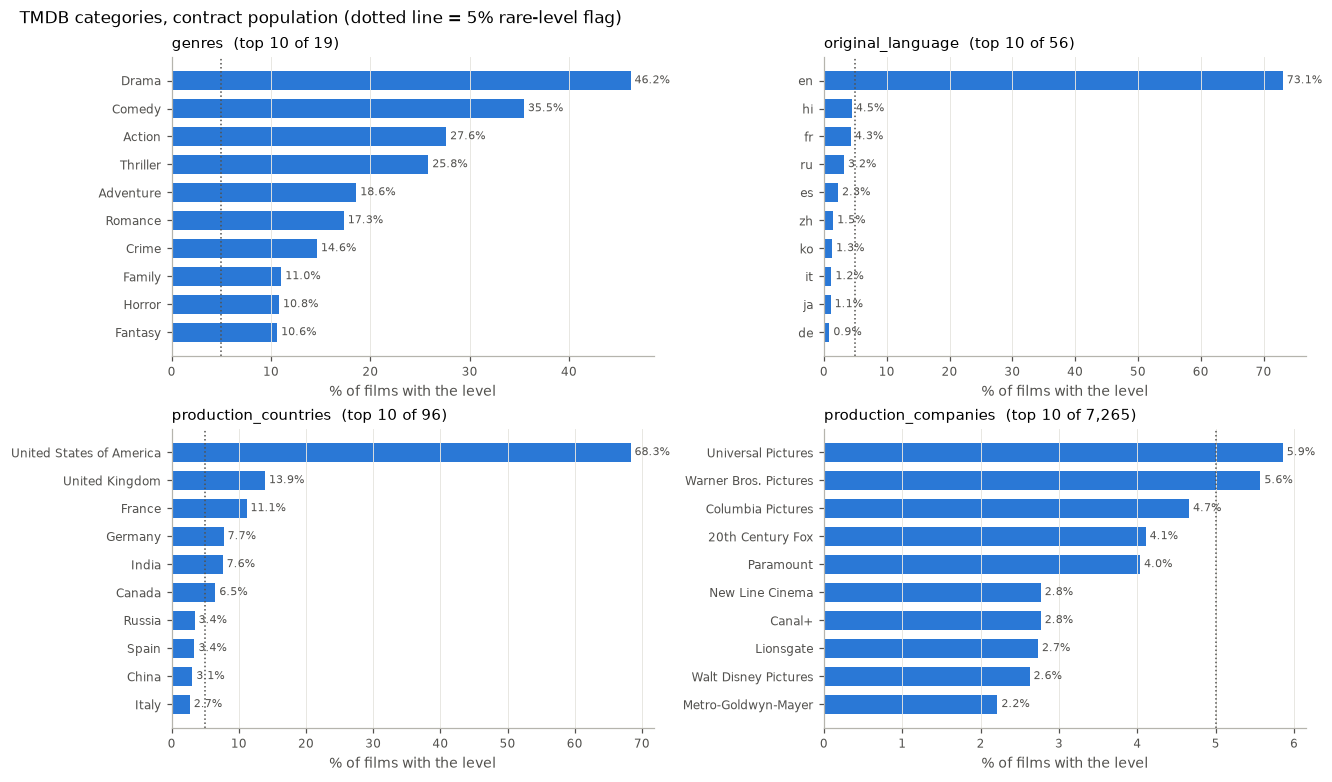

In [48]:
cat_specs = [("status", False), ("adult", False), ("original_language", False),
             ("genres", True), ("production_countries", True), ("spoken_languages", True),
             ("production_companies", True), ("keywords", True)]
rows, tmdb_counts = [], {}
for col, multi in cat_specs:
    row, vc = category_profile(pop[col], col, multi)
    rows.append(row)
    tmdb_counts[col] = vc
prof_tmdb_cat = pd.DataFrame(rows).set_index("field")
display(prof_tmdb_cat)

# Track-record sparsity: how many companies have only one film in the population?
per_company = tmdb_counts["production_companies"]
per_film = pop["production_companies"].str.split(",").str.len()
print(f"Production companies: {len(per_company):,} distinct; "
      f"{(per_company == 1).mean():.0%} appear in only one population film; "
      f"median {per_film.median():.0f} companies per film (max {per_film.max():.0f})")
print(f"Genres per film: median {pop['n_genres'].median():.0f}, max {pop['n_genres'].max():.0f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, col, title in zip(axes.ravel(),
                          ["genres", "original_language", "production_countries", "production_companies"],
                          ["genres", "original_language", "production_countries", "production_companies"]):
    count_plot(ax, tmdb_counts[col], pop[col].notna().sum(), title, xlabel="% of films with the level")
fig.suptitle("TMDB categories, contract population (dotted line = 5% rare-level flag)",
             x=0.01, ha="left", fontsize=11)
plt.show()

### 3e. TMDB identifier and free-text fields
These get uniqueness, duplicate and length checks only. An id is never averaged. `title` duplicates matter because the RT join (step 10) matches on title.

In [49]:
prof_tmdb_id = id_text_profile(pop, ["id", "imdb_id", "title", "original_title", "overview",
                                     "tagline", "homepage", "poster_path", "backdrop_path"])
display(prof_tmdb_id)
dup_titles = pop["title"].duplicated(keep=False)
print(f"title differs from original_title: {(pop['title'] != pop['original_title']).mean():.1%} of films")
print(f"films sharing a title with another population film: {dup_titles.sum()} "
      f"({pop.loc[dup_titles, 'title'].nunique()} titles); "
      f"same title and year: {pop.duplicated(['title', 'year'], keep=False).sum()}")
dup_imdb = pop["imdb_id"].dropna().duplicated(keep=False).sum()
if dup_imdb:
    flag("TMDB (population)", "imdb_id", "duplicate key", f"{dup_imdb} films share an imdb_id")
flag("TMDB (population)", "title", "duplicate key",
     f"{dup_titles.sum()} films share a title: the join needs year + runtime")
same_ty = pop.duplicated(["title", "year"], keep=False)
if same_ty.any():
    flag("TMDB (population)", "id", "same film under two ids?",
         f"{same_ty.sum()} films share title and year with another id")
    display(pop.loc[same_ty, ["id", "title", "year", "budget", "revenue", "runtime"]].sort_values("title"))

,% missing,unique values,rows sharing a value,median length (chars)
field,,,,
id,0.0,5766,0,5.0
imdb_id,2.2,5638,0,9.0
title,0.0,5691,149,13.0
original_title,0.0,5724,84,13.0
overview,0.9,5708,13,242.0
tagline,21.1,4522,54,33.0
homepage,53.6,2649,42,35.0
poster_path,0.6,5729,0,32.0
backdrop_path,3.7,5551,0,32.0


title differs from original_title: 22.1% of films
films sharing a title with another population film: 149 (74 titles); same title and year: 12


,id,title,year,budget,revenue,runtime
14214,467106,Bareilly Ki Barfi,2017.0,2740700,8050806,123
256454,1298885,Bareilly Ki Barfi,2017.0,2396334,5990835,122
3868,565770,Blue Beetle,2023.0,120000000,124818235,128
863970,1611344,Blue Beetle,2023.0,100000000,400000000,0
430151,1453985,Diggy and The Bandits,2001.0,447000000,12,207
432213,1453767,Diggy and The Bandits,2001.0,447000000,12,207
68,557,Spider-Man,2002.0,139000000,821708551,121
438426,1391422,Spider-Man,2002.0,139000000,821708551,121
57,634649,Spider-Man: No Way Home,2021.0,200000000,1921847111,148
705634,1791559,Spider-Man: No Way Home,2021.0,200000000,1921426073,0


### 3f. TMDB release date (contract population)
Range, missingness, placeholder days, and coverage by year. Release month is an allowed input, so its balance is checked too.

release_date: 2000-01-12 to 2023-12-21, missing 0, Jan 1 dates 19 (0.3%; 1/365 = 0.3% expected by chance)


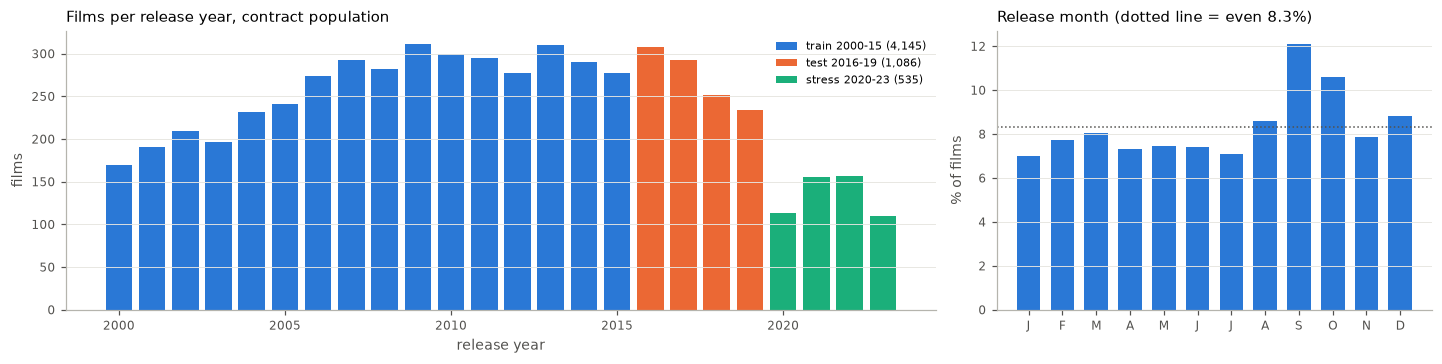

release_month,1,2,3,4,5,6,7,8,9,10,11,12
% of films,7.0,7.7,8.0,7.3,7.4,7.4,7.1,8.6,12.1,10.6,7.9,8.8


In [50]:
d = pop["release_dt"]
jan1 = ((d.dt.month == 1) & (d.dt.day == 1)).sum()
print(f"release_date: {d.min().date()} to {d.max().date()}, missing {d.isna().sum()}, "
      f"Jan 1 dates {jan1} ({jan1 / len(d):.1%}; 1/365 = 0.3% expected by chance)")
if jan1 / len(d) > 0.01:
    flag("TMDB (population)", "release_date", "placeholder date?", f"{jan1} films dated Jan 1")

month_share = pop["release_month"].value_counts(normalize=True).sort_index() * 100
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.2), width_ratios=[2, 1], layout="constrained")
for p, g in pop.groupby("period", observed=True):
    yc = g["year"].value_counts().sort_index()
    a1.bar(yc.index, yc.values, color=SERIES[p], width=0.8, label=f"{p} ({len(g):,})")
a1.set_title("Films per release year, contract population")
a1.set_xlabel("release year")
a1.set_ylabel("films")
a1.legend(fontsize=7, frameon=False)
a1.grid(axis="x", visible=False)
a2.bar(month_share.index, month_share.values, color=BLUE, width=0.7)
a2.axhline(100 / 12, color=INK2, ls=":", lw=1)
a2.set_xticks(range(1, 13), list("JFMAMJJASOND"))
a2.set_title("Release month (dotted line = even 8.3%)")
a2.set_ylabel("% of films")
a2.grid(axis="x", visible=False)
plt.show()
display(month_share.round(1).rename("% of films").to_frame().T)

### 3g. RT movies: all 16 fields (whole file)
The whole RT file is profiled, read only. Its 1,204 exact duplicate rows (0.8%, from 2c) are left in, since they're too few to move these statistics. `boxOffice` is stored as text like `$31.4M`, so it's parsed into dollars in memory to profile it.

boxOffice: 14,743 non-missing, 0 could not be parsed


,n,% missing,mean,median,std,min,Q1,Q3,max,IQR,skew,# above Q3+1.5 IQR,# below Q1-1.5 IQR,skew flag
field,,,,,,,,,,,,,,
audienceScore,73248,48.90,55.67,57.00,24.55,0.00,37.00,76.00,100.00,39.00,-0.23,0,0,False
tomatoMeter,33877,76.40,65.77,73.00,28.02,0.00,45.00,89.00,100.00,44.00,-0.65,0,0,True
runtimeMinutes,129431,9.70,93.71,92.00,28.13,1.00,84.00,103.00,"2,700.00",19.00,7.62,7999,6721,True
boxOffice_usd,14743,89.70,"18,295,173.54","651,400.00","48,142,839.92",0.00,"51,500.00","14,100,000.00","858,400,000.00","14,048,500.00",5.93,2166,0,True


scores outside 0-100: {'audienceScore': 0, 'tomatoMeter': 0}
runtimeMinutes = 0: 0; under 40 min (short film): 4,308
theatrical date in 2000-2023: 18,903 titles; streaming date before theatrical date: 439 titles


,% missing,multi-label,levels,top level,top level % of rows,levels < 5% of rows,% of rows in a level < 5%
field,,,,,,,
rating,90.2,False,10,R,55.3,7,6.4
originalLanguage,9.7,False,112,English,65.7,111,34.3
distributor,83.9,False,3693,Paramount Pictures,4.3,3693,100.0
soundMix,88.9,True,26,Surround,45.7,17,NaN
genre,7.7,True,37,Drama,42.1,29,NaN
director,2.9,True,64718,"(person, withheld)",2.6,64718,NaN
writer,37.1,True,74112,"(person, withheld)",0.2,74112,NaN


Directors: 64,718 distinct; 65% have one RT title; 90th percentile 4 titles; 6.8% of titles list 2+ directors


,% missing,unique values,rows sharing a value,median length (chars)
field,,,,
id,0.0,142052,2412,16.0
title,0.3,126403,26789,15.0
ratingContents,90.2,8353,6927,44.0


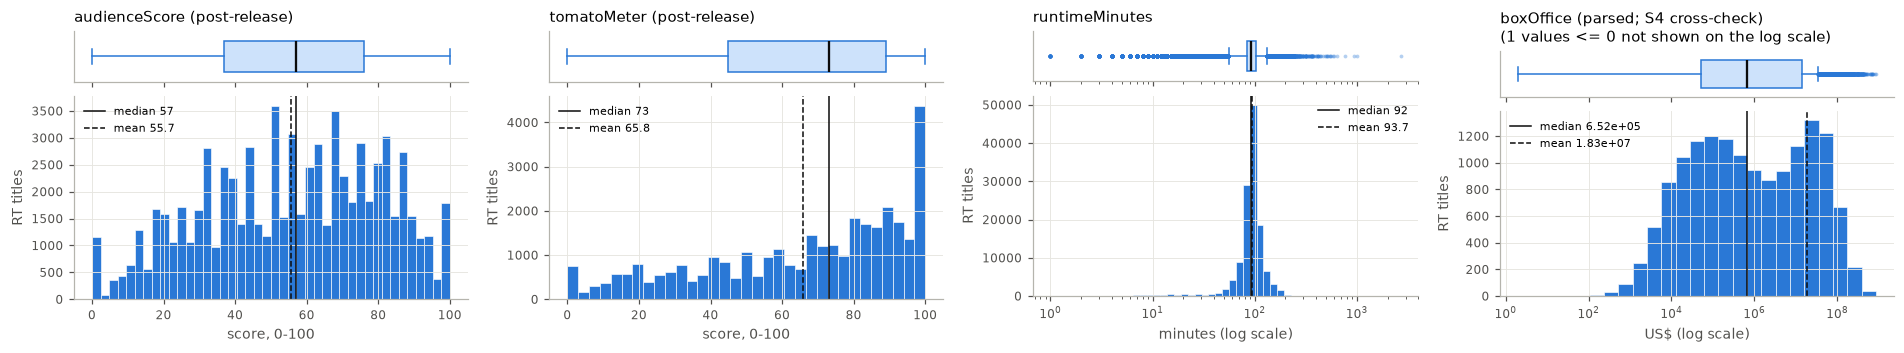

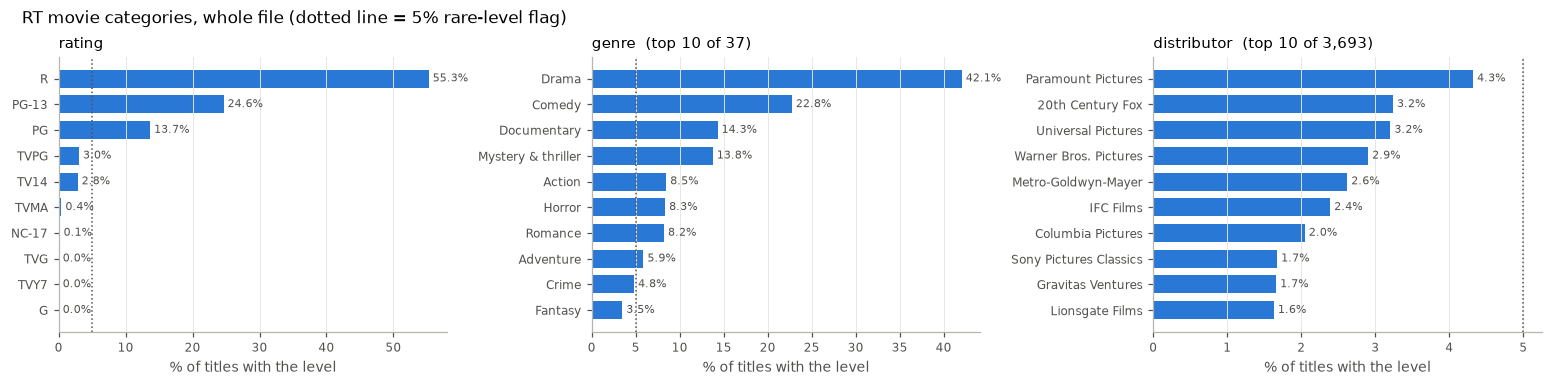

In [51]:
rt = rt_movies

def parse_money(s):
    m = s.str.extract(r"^\$([\d.]+)([KMB]?)$")
    return m[0].astype(float) * m[1].map({"": 1, "K": 1e3, "M": 1e6, "B": 1e9})

rt_num = rt[["audienceScore", "tomatoMeter", "runtimeMinutes"]].assign(boxOffice_usd=parse_money(rt["boxOffice"]))
unparsed = rt["boxOffice"].notna().sum() - rt_num["boxOffice_usd"].notna().sum()
print(f"boxOffice: {rt['boxOffice'].notna().sum():,} non-missing, {unparsed} could not be parsed")
if unparsed:
    flag("RT movies", "boxOffice", "unparseable text", f"{unparsed} values don't match $n.nK/M/B")

prof_rt_num = numeric_profile(rt_num, list(rt_num.columns))
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(prof_rt_num)
out_of_range = {c: int((~rt[c].dropna().between(0, 100)).sum()) for c in ["audienceScore", "tomatoMeter"]}
print("scores outside 0-100:", out_of_range)
rt_zero = (rt["runtimeMinutes"] == 0).sum()
print(f"runtimeMinutes = 0: {rt_zero}; under 40 min (short film): {(rt['runtimeMinutes'] < 40).sum():,}")

# Dates: order check and how much of the file falls in the contract years
theat = pd.to_datetime(rt["releaseDateTheaters"], errors="coerce")
stream = pd.to_datetime(rt["releaseDateStreaming"], errors="coerce")
stream_first = (stream < theat).sum()
print(f"theatrical date in 2000-2023: {theat.dt.year.between(2000, 2023).sum():,} titles; "
      f"streaming date before theatrical date: {stream_first:,} titles")
if stream_first:
    flag("RT movies", "releaseDateStreaming", "date order",
         f"{stream_first:,} titles list streaming before theatrical release")

rows, rt_counts = [], {}
for col, multi, hidden in [("rating", False, False), ("originalLanguage", False, False),
                           ("distributor", False, False), ("soundMix", True, False),
                           ("genre", True, False), ("director", True, True), ("writer", True, True)]:
    row, vc = category_profile(rt[col], col, multi, names_hidden=hidden)
    rows.append(row)
    rt_counts[col] = vc
prof_rt_cat = pd.DataFrame(rows).set_index("field")
display(prof_rt_cat)

# Director concentration, counts only (no names)
per_dir = rt_counts["director"]
multi_dir = rt["director"].dropna().str.contains(",").mean()
print(f"Directors: {len(per_dir):,} distinct; {(per_dir == 1).mean():.0%} have one RT title; "
      f"90th percentile {per_dir.quantile(0.9):.0f} titles; {multi_dir:.1%} of titles list 2+ directors")

prof_rt_id = id_text_profile(rt, ["id", "title", "ratingContents"])
display(prof_rt_id)

profile_grid([
    (rt_num["audienceScore"], "audienceScore (post-release)", "score, 0-100", False),
    (rt_num["tomatoMeter"], "tomatoMeter (post-release)", "score, 0-100", False),
    (rt_num["runtimeMinutes"], "runtimeMinutes", "minutes (log scale)", True),
    (rt_num["boxOffice_usd"], "boxOffice (parsed; S4 cross-check)", "US$ (log scale)", True),
], ylabel="RT titles", ncols=4)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), layout="constrained")
for ax, col in zip(axes, ["rating", "genre", "distributor"]):
    count_plot(ax, rt_counts[col], rt[col].notna().sum(), col, xlabel="% of titles with the level")
fig.suptitle("RT movie categories, whole file (dotted line = 5% rare-level flag)", x=0.01, ha="left", fontsize=11)
plt.show()

### 3h. RT reviews: all 11 fields (whole file)
All of these are post-release and can't be model inputs. They matter for the early-review test (step 11) and for judging the RT side of the join. Critic names are profiled by counts only.

Reviews cover 69,263 RT titles; 73,386 RT titles have no reviews; 297 reviews point to an id not in RT movies
creationDate: before 2000 542 reviews (of which year 1800 placeholders: 71)


scoreSentiment,NEGATIVE,POSITIVE,All
reviewState,,,
fresh,0,963799,963799
rotten,481164,0,481164
All,481164,963799,1444963


reviewState and scoreSentiment agree on 100.00% of reviews


,fraction (3/4),missing,letter grade (B+),bare number,other
% of reviews,58.4,30.1,11.0,0.3,0.2


,% missing,multi-label,levels,top level,top level % of rows,levels < 5% of rows,% of rows in a level < 5%
field,,,,,,,
isTopCritic,0.0,False,2,False,69.8,0,0.0
reviewState,0.0,False,2,fresh,66.7,0,0.0
scoreSentiment,0.0,False,2,POSITIVE,66.7,0,0.0
publicatioName,0.0,False,2707,New York Times,1.4,2707,100.0
criticName,0.0,False,15510,"(person, withheld)",0.9,15510,100.0


Critics: 15,510 distinct; median 4 reviews each; 31% wrote only one


,n,% missing,mean,median,std,min,Q1,Q3,max,IQR,skew,# above Q3+1.5 IQR,# below Q1-1.5 IQR,skew flag
field,,,,,,,,,,,,,,
reviews per RT title,69263,0.00,20.86,4.00,46.35,1.00,1.00,16.00,954.00,15.00,4.35,9398,0,True
reviewText length (chars),1375738,4.80,131.58,130.00,56.80,1.00,89.00,171.00,363.00,82.00,0.16,633,0,False


,% missing,unique values,rows sharing a value,median length (chars)
field,,,,
reviewId,0.0,1432569,24788,7.0
reviewUrl,14.6,1138350,141780,68.0
reviewText,4.8,1359771,29999,130.0


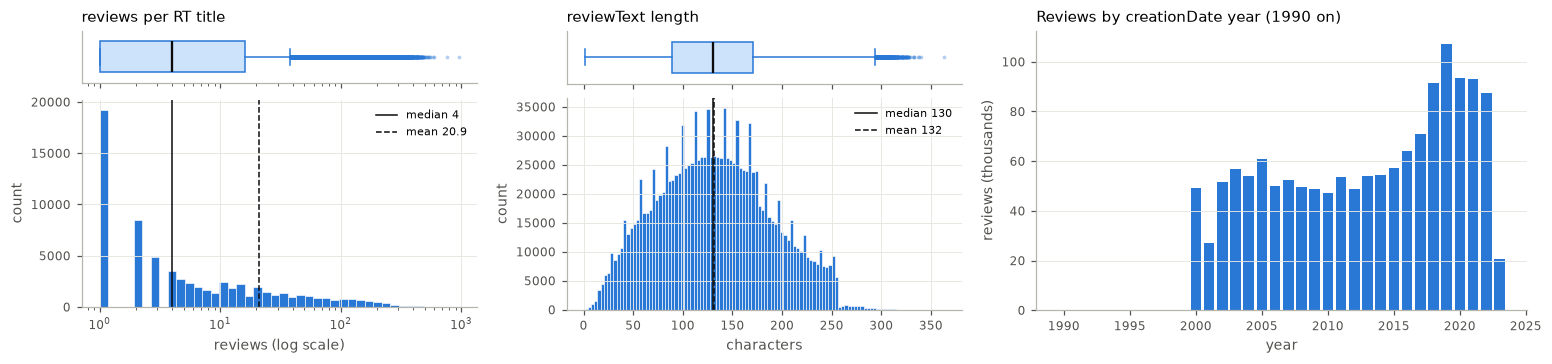

In [52]:
rv = rt_reviews
per_movie = rv["id"].value_counts()
no_reviews = (~rt["id"].isin(rv["id"])).sum()
orphans = (~rv["id"].isin(rt["id"])).sum()
print(f"Reviews cover {len(per_movie):,} RT titles; {no_reviews:,} RT titles have no reviews; "
      f"{orphans:,} reviews point to an id not in RT movies")
if orphans:
    flag("RT reviews", "id", "orphan key", f"{orphans:,} reviews have no matching RT movie")

cd = pd.to_datetime(rv["creationDate"], errors="coerce")
print(f"creationDate: before 2000 {(cd.dt.year < 2000).sum():,} reviews "
      f"(of which year 1800 placeholders: {(cd.dt.year == 1800).sum()})")

# reviewState vs scoreSentiment: are they the same field twice?
display(pd.crosstab(rv["reviewState"], rv["scoreSentiment"], margins=True))
agree = ((rv["reviewState"] == "fresh") == (rv["scoreSentiment"] == "POSITIVE")).mean()
print(f"reviewState and scoreSentiment agree on {agree:.2%} of reviews")
if agree > 0.99:
    flag("RT reviews", "scoreSentiment", "redundant", f"matches reviewState on {agree:.2%} of rows")

# originalScore formats
fmt = np.select(
    [rv["originalScore"].isna(),
     rv["originalScore"].str.fullmatch(r"\s*[\d.]+\s*/\s*[\d.]+\s*", na=False),
     rv["originalScore"].str.fullmatch(r"\s*[A-Fa-f][+-]?\s*", na=False),
     rv["originalScore"].str.fullmatch(r"\s*[\d.]+\s*", na=False)],
    ["missing", "fraction (3/4)", "letter grade (B+)", "bare number"], default="other")
fmt_share = pd.Series(fmt).value_counts(normalize=True).mul(100).round(1)
display(fmt_share.rename("% of reviews").to_frame().T)
flag("RT reviews", "originalScore", "mixed formats",
     "; ".join(f"{k} {v}%" for k, v in fmt_share.items()))

rows, rv_counts = [], {}
for col, hidden in [("isTopCritic", False), ("reviewState", False), ("scoreSentiment", False),
                    ("publicatioName", False), ("criticName", True)]:
    row, vc = category_profile(rv[col], col, names_hidden=hidden)
    rows.append(row)
    rv_counts[col] = vc
prof_rv_cat = pd.DataFrame(rows).set_index("field")
display(prof_rv_cat)
per_critic = rv_counts["criticName"]
print(f"Critics: {len(per_critic):,} distinct; median {per_critic.median():.0f} reviews each; "
      f"{(per_critic == 1).mean():.0%} wrote only one")

text_len = rv["reviewText"].str.len()
prof_rv_num = pd.concat([
    numeric_profile(per_movie.rename("reviews per RT title").to_frame(), ["reviews per RT title"]),
    numeric_profile(text_len.rename("reviewText length (chars)").to_frame(), ["reviewText length (chars)"]),
])
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(prof_rv_num)
prof_rv_id = id_text_profile(rv, ["reviewId", "reviewUrl", "reviewText"])
display(prof_rv_id)

year_counts = cd[cd.dt.year >= 1990].dt.year.value_counts().sort_index()
fig = plt.figure(figsize=(14, 3.2), layout="constrained")
sf1, sf2, sf3 = fig.subfigures(1, 3, width_ratios=[1, 1, 1.2])
for sf, x, title, xlabel, log in [
        (sf1, per_movie, "reviews per RT title", "reviews (log scale)", True),
        (sf2, text_len, "reviewText length", "characters", False)]:
    ab, ah = sf.subplots(2, 1, sharex=True, height_ratios=[1, 4])
    box_hist(ab, ah, x, title, xlabel, "count", log)
ax = sf3.subplots()
ax.bar(year_counts.index, year_counts.values / 1000, color=BLUE, width=0.8)
ax.set_title("Reviews by creationDate year (1990 on)")
ax.set_xlabel("year")
ax.set_ylabel("reviews (thousands)")
ax.grid(axis="x", visible=False)
plt.show()

### 3i. Flag register
Every flag from 3b–3h in one table: the skew and rare-level review flags, all missingness, and the range, order and key checks above. This is the hand-off to the readiness gate (step 12) and the cleaning ledger (step 13). Dispositions are written below it.

In [53]:
reg = list(FLAGS)
for prof, file in [(prof_tmdb_num, "TMDB (population)"), (prof_rt_num, "RT movies"), (prof_rv_num, "RT reviews")]:
    for f, r in prof.iterrows():
        if r["skew flag"]:
            reg.append({"file": file, "field": f, "issue": "skew > 0.5",
                        "evidence": f"skew {r['skew']:.2f}; median {r['median']:,.3g} vs mean {r['mean']:,.3g}"})
        if r["% missing"] > 0:
            reg.append({"file": file, "field": f, "issue": "missing", "evidence": f"{r['% missing']}% missing"})
for prof, file in [(prof_tmdb_cat, "TMDB (population)"), (prof_rt_cat, "RT movies"), (prof_rv_cat, "RT reviews")]:
    for f, r in prof.iterrows():
        if r["levels"] == 1:
            reg.append({"file": file, "field": f, "issue": "constant", "evidence": "one level only"})
        elif r["levels < 5% of rows"] > 0:
            reg.append({"file": file, "field": f, "issue": "rare levels",
                        "evidence": f"{r['levels < 5% of rows']:,} of {r['levels']:,} levels under 5% of rows"})
        if r["% missing"] > 0:
            reg.append({"file": file, "field": f, "issue": "missing", "evidence": f"{r['% missing']}% missing"})
for prof, file in [(prof_tmdb_id, "TMDB (population)"), (prof_rt_id, "RT movies"), (prof_rv_id, "RT reviews")]:
    for f, r in prof.iterrows():
        if r["% missing"] > 0:
            reg.append({"file": file, "field": f, "issue": "missing", "evidence": f"{r['% missing']}% missing"})

register = pd.DataFrame(reg).drop_duplicates(["file", "field", "issue"]).sort_values(["file", "field"])
with pd.option_context("display.max_rows", 120, "display.max_colwidth", 90):
    display(register.reset_index(drop=True))
print(f"{len(register)} flags across {register[['file', 'field']].drop_duplicates().shape[0]} fields")
register.groupby(["file", "issue"]).size().unstack(fill_value=0)

,file,field,issue,evidence
0,RT movies,audienceScore,missing,48.9% missing
1,RT movies,boxOffice_usd,skew > 0.5,skew 5.93; median 6.51e+05 vs mean 1.83e+07
2,RT movies,boxOffice_usd,missing,89.7% missing
3,RT movies,director,rare levels,"64,718 of 64,718 levels under 5% of rows"
4,RT movies,director,missing,2.9% missing
5,RT movies,distributor,rare levels,"3,693 of 3,693 levels under 5% of rows"
6,RT movies,distributor,missing,83.9% missing
7,RT movies,genre,rare levels,29 of 37 levels under 5% of rows
8,RT movies,genre,missing,7.7% missing
9,RT movies,originalLanguage,rare levels,111 of 112 levels under 5% of rows


70 flags across 49 fields


issue,constant,date order,duplicate key,"estimate, not audited",extreme values,implausible range,majority class,missing,mixed formats,orphan key,rare levels,redundant,same film under two ids?,skew > 0.5,zero = unknown
file,,,,,,,,,,,,,,,
RT movies,0,1,0,0,0,0,0,13,0,0,7,0,0,3,0
RT reviews,0,0,0,0,0,0,0,3,1,1,2,1,0,1,0
TMDB (population),2,0,1,1,1,2,1,13,0,0,6,0,1,8,1


### 3j. What the profile shows (facts from the outputs above)

**The label**
1. **Most films are money-losers at 2.5×:** 64.6% overall (train 65.2%, test 59.8%, stress 69.5%). The median film earns 1.59× its budget. Because losers are the majority, a 20% review capacity can hold at most about 31% of them. That's the ceiling on the contract's capture metric. The random baseline catches 20%.
2. **Some losses are data errors, not flops.** 24 films report revenue under $1,000, and 244 under $100,000. 179 films earned less than 1% of their budget. The lowest are obvious junk: "Aquajots" lists a $100M budget and $1 of revenue. At the other end, five films earned more than 100× their budget, and at least one looks like a typo: "Vacancy" (2018) shows $903M on a $1M budget. Left in, these errors inflate the loser rate.
3. **Possible double entries:** 6 pairs of TMDB ids share a title and year. Some look like the same film entered twice (e.g., "Diggy and The Bandits," with identical values). Others are different films with the same name (e.g., two "Blue Beetle" 2023 entries with different numbers).

**Inputs allowed at the financing decision**
4. **Budget:** median $16M, mean $34M, skew 4.2. 4,330 of 5,766 budgets (75%) are round $1M figures, which suggests public estimates, not audited costs.
5. **Runtime:** 52 films have 0 (unknown), 36 are under 60 minutes, and the maximum is 999. Runtime is the final cut, not the planned one (weak link 4).
6. **Categories:** English is the original language of 73% of films, and the other 55 languages each fall under 5%. Drama appears on 46% of films; 5 of 19 genres are rare. **7,265 production companies, and 66% appear in only one film.** A company track record built from earlier films will be empty for most companies, and the same check is needed for directors after the join.
7. **Release month** is uneven: September has 12.1% of films and October 10.6%, against 8.3% if spread evenly.

**Post-release and join fields**
8. **Vote fields:** 125 films have 0 votes and a 0 vote average. They're prohibited inputs and aren't used to filter the population. That's the earlier AI correction.
9. **RT movies:** `boxOffice` is 89.7% missing and every value that is present parses. 4,308 RT titles run under 40 minutes (shorts). 439 titles list streaming before theatrical release. RT has 64,718 directors; 65% have only one title, and 6.8% of titles list two or more directors.
10. **RT reviews:** `scoreSentiment` repeats `reviewState` on 100% of rows. `originalScore` mixes fractions, letter grades and blanks. 297 reviews point to an RT id that doesn't exist. 73,386 RT titles have no reviews at all.

**Dispositions, the cleaning treatment for each flag, and the phase gate are decided by Matt** (Ch 6 decision gates) and recorded below once reviewed.

### 3k. Dispositions and phase gate (approved by Matt Sorensen, 2026-11-18)
These are the next-phase treatments for each flag in 3i. **None are applied here.** Phase 3 (the cleaning ledger, step 13) carries them out and logs the row counts.

| # | Flag | Evidence (3b–3h) | Disposition | Treatment in Phase 3 | Verification check |
|---|---|---|---|---|---|
| 1 | Revenue errors | 24 films report revenue < $1,000 and 244 < $100,000; 179 earned < 1% of budget | Requires repair | Hand-check a sample of films below 0.01×. Set a minimum revenue threshold, check it against RT box office for films that join, and run the analysis with and without these films. | Sample error rate; loser rate with vs. without the threshold |
| 2 | Extreme hits | 5 films above 100× (e.g., "Vacancy" 2018: $903M on $1M) | Requires source clarification | Hand-check all 5 and keep only the real ones. | Each one confirmed or excluded, with the reason |
| 3 | 64.6% losers at 2.5× | A 20% flag can catch at most about 31% of losers | Usable with a limitation | Keep the contract as is. State the 31% ceiling and lean on precision at 20%. Any change to the label needs a dated contract amendment. | Ceiling recomputed on the test films |
| 4 | Double ids | 6 pairs share a title and year | Requires repair | Same title, year, budget and revenue means the same film: keep one copy. Different values means different films: keep both. | Pair count before and after |
| 5 | Runtime | 52 zeros, 36 under 60 min, max 999 | Requires repair | Treat 0 and 999 as missing, with a missing-value indicator. Hand-check the under-60s. No invented values. | Count of missing runtimes after the rule |
| 6 | Round budgets | 75% are round $1M figures (likely estimates) | Usable with a limitation | No change. The budget-tier robustness check is already in the contract. | Model refit on budget tiers (Phase 4) |
| 7 | Rare categories | Language: English 73%, 55 others each < 5%. Country: US 68%. Genres: 5 of 19 rare. | Usable as defined, after grouping | Language: English vs. other. Country: US vs. other. All 19 genres kept, one yes/no column each. | Level counts after grouping |
| 8 | Thin track records | 66% of production companies appear in only one film | Usable with a limitation | Track record built from earlier films only, plus a "no earlier films" indicator. Director sparsity is checked after the join. | Share of films with no earlier films, by period |
| 9 | RT movies | 4,308 shorts; 439 titles with streaming before theatrical; `boxOffice` 89.7% missing | Usable with a limitation | Shorts drop out through the join. The date-order issue doesn't affect us. `boxOffice` is used only for the S4 check. | Join match counts (step 10) |
| 10 | RT reviews | `scoreSentiment` repeats `reviewState`; mixed `originalScore` formats; 297 orphan reviews | Not fit as model input | Drop `scoreSentiment` as redundant. Reviews are used only for the early-review test (step 11). | None needed |
| 11 | Vote fields | 125 films with 0 votes | Not fit for this decision | Not used: post-release, and filtering on them was the earlier AI correction. | None needed |
| 12 | Text and URL fields | Overview, tagline, homepage, poster and backdrop paths | Not fit for this decision | Not used; left out of the prepared file. | None needed |

**Phase gate: CONTINUE** to step 10 (build and verify the RT join). The data supports the decision population, but the label needs the revenue repairs in rows 1–2 before modeling. The readiness verdict comes at step 12, after the S4 missing-revenue check.

## 4. Build and verify the TMDB-RT join (plan step 10)

**Why join at all:** TMDB has no director field. The focal factor (director track record) comes from RT's `director`, and the S4 missing-revenue check needs RT's `boxOffice`. Neither file shares an id with the other, so films are matched on **title, release year (±1) and runtime**.

**Rules, fixed before looking at the results:**
1. Titles are normalized: accents removed, lower case, `&` → `and`, punctuation dropped, spaces collapsed.
2. A candidate pair needs the same normalized title (TMDB `title`, or `original_title` as a fallback) and an RT year within ±1 of the TMDB year. The RT year is the theatrical date's year, or the streaming date's year when there's no theatrical date.
   - **2b (added 2026-11-18, after the first pass):** an RT record with **only a streaming date** may have a streaming year later than TMDB year + 1, **if the runtimes agree within 5 minutes.** *Why:* the first pass left 447 films unmatched whose title was in RT. Most were international films whose only RT date is a streaming date 2–10 years after release (e.g., "English Vinglish," 2012 release, 2016 RT streaming date, 134 vs. 133 minutes). The runtime check replaces the year as the second piece of evidence. This rule was set by looking at match quality, never at the outcome.
3. If a film has several candidates, a title match beats an `original_title` match, rule 2 beats rule 2b, then the closest year wins, then the closest runtime.
4. **One-to-one:** if one RT record is the best match for two TMDB films, both pairs are dropped as ambiguous rather than guessed.
5. **Verification:** a random sample of 50 matched pairs is checked by hand, plus 10 extra pairs drawn only from rule 2b (a random 50 would include just 2 or 3 of them). Stop condition S3 is judged on the random 50: more than 10% wrong matches drops the RT join, and production-company track record becomes the focal factor. If 2 or more of the 10 rule-2b pairs are wrong, rule 2b is dropped.

This section writes two files to `../data/clean/`: the crosswalk (TMDB id ↔ RT id) and the hand-check sheet. The hand-check sheet is written **once** and never overwritten, because Matt fills it in by hand.

In [54]:
import re
import unicodedata

def norm_title(s):
    s = s.fillna("").astype(str).map(
        lambda x: unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode())
    s = s.str.lower().str.replace("&", " and ", regex=False)
    s = s.str.replace(r"[^a-z0-9 ]", " ", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

# RT side: one row per RT id (2c: 1,206 repeated ids, all but 2 exact copies; keep the first)
rtj = rt_movies.drop_duplicates("id").copy()
rt_theat = pd.to_datetime(rtj["releaseDateTheaters"], errors="coerce").dt.year
rt_stream = pd.to_datetime(rtj["releaseDateStreaming"], errors="coerce").dt.year
rtj["rt_year"] = rt_theat.fillna(rt_stream)
rtj["rt_year_source"] = np.where(rt_theat.notna(), "theatrical", np.where(rt_stream.notna(), "streaming", "none"))
rtj["key"] = norm_title(rtj["title"])
rtj = rtj[rtj["key"].ne("") & rtj["rt_year"].notna()]

# TMDB side: the contract population
tj = pop[["id", "title", "original_title", "year", "runtime", "budget", "revenue", "period"]].copy()
tj["key_title"] = norm_title(tj["title"])
tj["key_orig"] = norm_title(tj["original_title"])

print(f"RT records usable for matching: {len(rtj):,} of {rt_movies['id'].nunique():,} unique ids "
      f"(year source: {rtj['rt_year_source'].value_counts().to_dict()})")
print(f"TMDB films to match: {len(tj):,}")

RT records usable for matching: 83,513 of 142,052 unique ids (year source: {'streaming': 53012, 'theatrical': 30501})
TMDB films to match: 5,766


In [55]:
# Candidate pairs: same normalized title (title first, original_title as fallback), year within +/-1
rt_cols = ["id", "key", "title", "rt_year", "rt_year_source", "runtimeMinutes", "director", "boxOffice"]
rt_side = rtj[rt_cols].rename(columns={"id": "rt_id", "title": "rt_title"})
cands = []
for key_col, how in [("key_title", "title"), ("key_orig", "original_title")]:
    c = tj.merge(rt_side, left_on=key_col, right_on="key", how="inner")
    c["matched_on"] = how
    cands.append(c)
cands = pd.concat(cands, ignore_index=True)
signed = cands["rt_year"] - cands["year"]
cands["year_diff"] = signed.abs()
cands["runtime_diff"] = (cands["runtimeMinutes"] - cands["runtime"].replace(0, np.nan)).abs()
rule2 = cands["year_diff"] <= 1
rule2b = (cands["rt_year_source"] == "streaming") & (signed > 1) & (cands["runtime_diff"] <= 5)
cands["rule"] = np.where(rule2, "2: year +/-1", np.where(rule2b, "2b: later streaming + runtime", None))
cands = cands[rule2 | rule2b].copy()

# Best candidate per TMDB film: title before original_title, rule 2 before 2b, closest year, closest runtime
cands["title_rank"] = cands["matched_on"].map({"title": 0, "original_title": 1})
cands["rule_rank"] = cands["rule"].str.startswith("2b").astype(int)
cands = cands.sort_values(["id", "title_rank", "rule_rank", "year_diff", "runtime_diff"], na_position="last")
n_cands = cands.groupby("id")["rt_id"].nunique()
best = cands.drop_duplicates("id").copy()
best["n_candidates"] = best["id"].map(n_cands)

# One-to-one: an RT record claimed by two TMDB films is ambiguous; drop both
claimed = best["rt_id"].duplicated(keep=False)
ambiguous = best[claimed]
xwalk = best[~claimed].copy()

summary = pd.Series({
    "TMDB films in population": len(tj),
    "films with >= 1 candidate": best["id"].nunique(),
    "dropped: RT record claimed twice": ambiguous["id"].nunique(),
    "matched 1:1": len(xwalk),
    "  of which by rule 2b (later streaming + runtime)": int(xwalk["rule"].str.startswith("2b").sum()),
    "  of which matched on original_title": int((xwalk["matched_on"] == "original_title").sum()),
    "  of which had > 1 candidate": int((xwalk["n_candidates"] > 1).sum()),
    "unmatched": len(tj) - len(xwalk),
}, name="films")
display(summary.to_frame())
print(f"Match rate: {len(xwalk) / len(tj):.1%}")

,films
TMDB films in population,5766
films with >= 1 candidate,4687
dropped: RT record claimed twice,14
matched 1:1,4673
of which by rule 2b (later streaming + runtime),241
of which matched on original_title,12
of which had > 1 candidate,277
unmatched,1093


Match rate: 81.0%


### 4a. Who gets matched?
A join that matches big films more often than small ones would bias everything built on it, including the director track record. So the match rate is checked by period and by budget tier. Unmatched films are split into "title not found in RT" and "title found, but the year is outside ±1".

,films,match_rate
period,,
train 2000-15,4145,82.3
test 2016-19,1086,81.5
stress 2020-23,535,70.5


,films,match_rate
budget_tier,,
$1-5M,1214,58.3
$5-20M,1903,82.2
$20-60M,1622,90.6
$60M+,1027,90.7


Loser rate (%) by matched status: {False: 68.3, True: 63.7}


,unmatched films
title not in RT,853
"title in RT, but year and runtime rules not met",226
ambiguous (RT record claimed twice),14


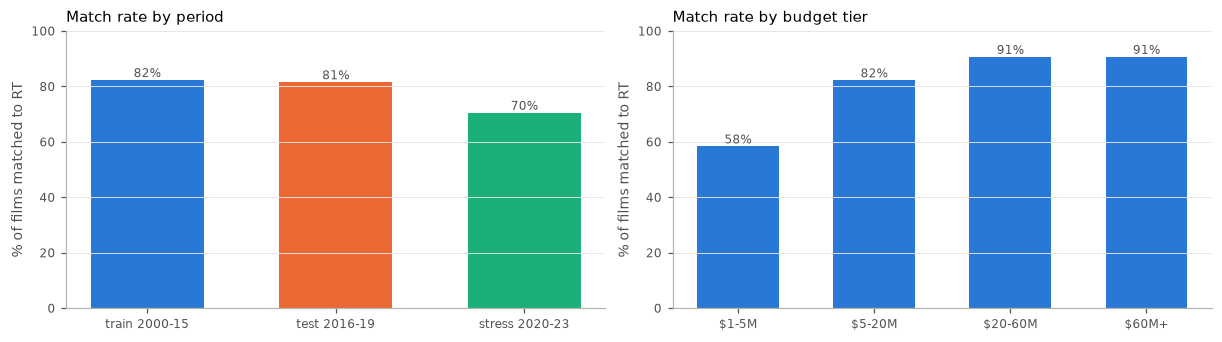

In [56]:
tj["matched"] = tj["id"].isin(xwalk["id"])
tj["budget_tier"] = pd.cut(tj["budget"], [1e6, 5e6, 20e6, 60e6, np.inf], right=False,
                           labels=["$1-5M", "$5-20M", "$20-60M", "$60M+"])
by_period = tj.groupby("period", observed=True)["matched"].agg(films="size", match_rate="mean")
by_tier = tj.groupby("budget_tier", observed=True)["matched"].agg(films="size", match_rate="mean")
display(by_period.assign(match_rate=lambda d: (100 * d["match_rate"]).round(1)))
display(by_tier.assign(match_rate=lambda d: (100 * d["match_rate"]).round(1)))

# Does matching depend on the outcome? (A coverage check: it decides whether the director
# feature is missing at random, not a test of any input's effect.)
loser_by_match = pop.assign(matched=tj["matched"]).groupby("matched")["money_loser"].mean().mul(100).round(1)
print("Loser rate (%) by matched status:", loser_by_match.to_dict())

unmatched = tj[~tj["matched"]]
title_in_rt = unmatched["key_title"].isin(rtj["key"]) | unmatched["key_orig"].isin(rtj["key"])
in_amb = unmatched["id"].isin(ambiguous["id"])
reasons = pd.Series({
    "title not in RT": int((~title_in_rt).sum()),
    "title in RT, but year and runtime rules not met": int((title_in_rt & ~in_amb).sum()),
    "ambiguous (RT record claimed twice)": int(in_amb.sum()),
}, name="unmatched films")
display(reasons.to_frame())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3), layout="constrained")
for ax, tbl, title in [(a1, by_period, "Match rate by period"), (a2, by_tier, "Match rate by budget tier")]:
    colors = [SERIES[p] for p in tbl.index] if ax is a1 else BLUE
    ax.bar(tbl.index.astype(str), 100 * tbl["match_rate"], color=colors, width=0.6)
    for i, v in enumerate(100 * tbl["match_rate"]):
        ax.text(i, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of films matched to RT")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
plt.show()

### 4b. Do the matched pairs agree?
If the pairs are the same film, the two sources should agree on year and runtime, and RT's domestic box office should track TMDB's worldwide revenue. RT box office is domestic (US) only, so it's expected to be **lower** than TMDB's worldwide figure. A matched pair where RT is clearly *higher* points to a wrong match or a bad TMDB revenue.

,% of matched pairs
same year,79.3
year differs by 1,15.6
year differs by 2+ (rule 2b),5.2
runtime within 5 min,92.9
runtime differs by > 15 min,1.1
runtime missing on either side,0.7


Pairs with RT box office: 3,833; Spearman(RT box, TMDB revenue) = 0.898; median RT/TMDB ratio = 0.50; RT > 1.1 x TMDB in 44 pairs
TMDB revenue within 2% of RT domestic box office: 396 pairs (10.3%). Loser rate 87% in these pairs vs 57% in the rest.


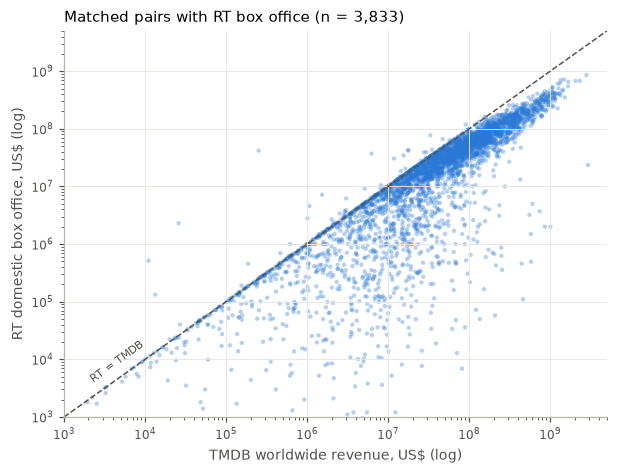

In [57]:
agree = pd.Series({
    "same year": (xwalk["year_diff"] == 0).mean(),
    "year differs by 1": (xwalk["year_diff"] == 1).mean(),
    "year differs by 2+ (rule 2b)": (xwalk["year_diff"] >= 2).mean(),
    "runtime within 5 min": (xwalk["runtime_diff"] <= 5).mean(),
    "runtime differs by > 15 min": (xwalk["runtime_diff"] > 15).mean(),
    "runtime missing on either side": xwalk["runtime_diff"].isna().mean(),
}).mul(100).round(1).rename("% of matched pairs")
display(agree.to_frame())

xwalk["rt_box_usd"] = parse_money(xwalk["boxOffice"])
both = xwalk.dropna(subset=["rt_box_usd"])
both = both[both["rt_box_usd"] > 0]
ratio = both["rt_box_usd"] / both["revenue"]
print(f"Pairs with RT box office: {len(both):,}; Spearman(RT box, TMDB revenue) = "
      f"{both['rt_box_usd'].corr(both['revenue'], method='spearman'):.3f}; "
      f"median RT/TMDB ratio = {ratio.median():.2f}; RT > 1.1 x TMDB in {(ratio > 1.1).sum()} pairs")
flag("Join", "rt_box vs revenue", "RT higher than TMDB",
     f"{(ratio > 1.1).sum()} pairs where domestic RT > 1.1 x worldwide TMDB: wrong match or bad TMDB revenue")

# Pairs where TMDB "worldwide" revenue equals RT domestic box office: TMDB may hold domestic only
same = ratio.between(0.98, 1.02)
loser_same = both.loc[same, "id"].map(pop.set_index("id")["money_loser"]).mean()
loser_rest = both.loc[~same, "id"].map(pop.set_index("id")["money_loser"]).mean()
print(f"TMDB revenue within 2% of RT domestic box office: {same.sum():,} pairs ({same.mean():.1%}). "
      f"Loser rate {loser_same:.0%} in these pairs vs {loser_rest:.0%} in the rest.")
flag("TMDB (population)", "revenue", "domestic-only revenue?",
     f"{same.sum():,} matched films have TMDB revenue within 2% of RT domestic box office: "
     "worldwide revenue may be understated, so some may be mislabelled as losers")

fig, ax = plt.subplots(figsize=(5.5, 4.2), layout="constrained")
ax.scatter(both["revenue"], both["rt_box_usd"], s=8, color=BLUE, alpha=0.35, edgecolors="none")
lims = [1e3, 5e9]
ax.plot(lims, lims, color=INK2, lw=1, ls="--")
ax.text(2e3, 4e3, "RT = TMDB", fontsize=7, color=INK2, rotation=36)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("TMDB worldwide revenue, US$ (log)")
ax.set_ylabel("RT domestic box office, US$ (log)")
ax.set_title(f"Matched pairs with RT box office (n = {len(both):,})")
plt.show()

### 4c. Save the crosswalk and the hand-check sheet
The crosswalk is rebuilt on every run. The hand-check sheet holds a random sample of 50 matched pairs plus 10 extra rule-2b pairs (seed 560); the `sample` column says which is which. It is written only if it doesn't exist yet, so Matt's answers are never overwritten. Each row has links to both websites.

**How to fill it in:** open `data/clean/join_handcheck.csv` in Excel. For each row, compare the two titles, years, runtimes and the RT director, and use the links if unsure. Put **Y** (same film) or **N** (different film) in `correct`, and add a short `note` for any N. Save as CSV.

In [58]:
CLEAN.mkdir(parents=True, exist_ok=True)
xw_out = xwalk[["id", "rt_id", "matched_on", "rule", "year_diff", "runtime_diff", "n_candidates"]].rename(
    columns={"id": "tmdb_id"})
xw_out.to_csv(CLEAN / "tmdb_rt_crosswalk.csv", index=False)
print(f"Wrote crosswalk: {len(xw_out):,} pairs -> {CLEAN / 'tmdb_rt_crosswalk.csv'}")

HANDCHECK = CLEAN / "join_handcheck.csv"
if HANDCHECK.exists():
    print(f"{HANDCHECK.name} already exists; left untouched (contains Matt's answers).")
else:
    rand50 = xwalk.sample(50, random_state=560).assign(sample="random 50")
    pool_2b = xwalk[xwalk["rule"].str.startswith("2b") & ~xwalk["id"].isin(rand50["id"])]
    extra = pool_2b.sample(10, random_state=560).assign(sample="extra rule 2b")
    sample = pd.concat([rand50, extra])
    sheet = pd.DataFrame({
        "sample": sample["sample"], "rule": sample["rule"],
        "tmdb_id": sample["id"], "tmdb_title": sample["title"], "tmdb_year": sample["year"].astype(int),
        "tmdb_runtime": sample["runtime"],
        "rt_id": sample["rt_id"], "rt_title": sample["rt_title"], "rt_year": sample["rt_year"].astype(int),
        "rt_runtime": sample["runtimeMinutes"], "rt_director": sample["director"],
        "tmdb_link": "https://www.themoviedb.org/movie/" + sample["id"].astype(str),
        "rt_link": "https://www.rottentomatoes.com/m/" + sample["rt_id"],
        "correct": "", "note": "",
    })
    sheet.to_csv(HANDCHECK, index=False)
    print(f"Wrote {len(sheet)} pairs for hand-checking -> {HANDCHECK}")

Wrote crosswalk: 4,673 pairs -> ..\data\clean\tmdb_rt_crosswalk.csv
join_handcheck.csv already exists; left untouched (contains Matt's answers).


### 4d. Hand-check result (stop condition S3)
Reads Matt's completed sheet. With only 50 pairs, the error rate is uncertain, so it's reported with a 95% Wilson interval next to the 10% threshold.

In [59]:
hc = pd.read_csv(HANDCHECK, dtype={"correct": str, "note": str})
hc["answer"] = hc["correct"].fillna("").str.strip().str.upper()
if not hc["answer"].isin(["Y", "N"]).all():
    print(f"Hand-check pending: {hc['answer'].isin(['Y', 'N']).sum()} of {len(hc)} rows answered. "
          f"Fill in {HANDCHECK.name}, then rerun.")
else:
    def wilson(k, n, z=1.96):
        p = k / n
        centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
        half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
        return p, max(0, centre - half), centre + half

    r50 = hc[hc["sample"] == "random 50"]
    k = int(r50["answer"].eq("N").sum())
    p, lo, hi = wilson(k, len(r50))
    print(f"Random 50: {k} wrong = {p:.0%} (95% Wilson CI {lo:.0%} to {hi:.0%})")
    print("S3 (> 10% wrong):", "TRIGGERED: drop the RT join" if p > 0.10 else "not triggered: keep the RT join")
    b = hc[hc["rule"].str.startswith("2b")]
    kb = int(b["answer"].eq("N").sum())
    print(f"Rule 2b pairs checked (extra 10 + any in the random 50): {kb} wrong of {len(b)} -> "
          + ("drop rule 2b" if kb >= 2 else "keep rule 2b"))
    if hc["answer"].eq("N").any():
        display(hc[hc["answer"].eq("N")])

Random 50: 0 wrong = 0% (95% Wilson CI 0% to 7%)
S3 (> 10% wrong): not triggered: keep the RT join
Rule 2b pairs checked (extra 10 + any in the random 50): 0 wrong of 11 -> keep rule 2b


### 4e. Join findings and verdict (hand-check by Matt Sorensen, 2026-11-19)

1. **Coverage:** 4,673 of 5,766 films (81.0%) matched one-to-one. 241 of them came through rule 2b. 14 films were dropped as ambiguous rather than guessed.
2. **Accuracy (stop condition S3):** Matt checked 60 pairs by hand: the random 50 and 10 extra rule-2b pairs. **0 of the random 50 were wrong (0%, 95% Wilson CI 0% to 7%).** Even the top of that interval is under the 10% threshold, so **S3 is not triggered: the RT join stays, and director track record stays the focal factor.** Rule 2b: 0 wrong of 11 checked, so it stays.
3. **Agreement:** 79% of pairs have the same year and 93% have runtimes within 5 minutes. RT domestic box office tracks TMDB revenue closely (Spearman 0.898, median ratio 0.50, as expected for domestic vs. worldwide).
4. **Coverage isn't even.** 58% of $1–5M films match, against 91% of $60M+ films, and the 2020–23 stress films match at 70.5%. Matched films are losers slightly less often than unmatched films (63.7% vs. 68.3%). Director track record will therefore be missing more often for small films and losers, so Phase 3 needs a "director unknown" indicator, not a dropped row.
5. **New label risk:** for 396 matched films (10.3%), TMDB "worldwide" revenue equals RT *domestic* box office within 2%. 87% of them are labelled losers, against 57% of the rest. Their foreign earnings are probably missing, which would make some false losers. This joins the revenue repairs (3k rows 1–2) and goes to the step 12 readiness gate.

**Outputs:** `data/clean/tmdb_rt_crosswalk.csv` (4,673 pairs, rebuilt each run) and `data/clean/join_handcheck.csv` (Matt's 60 answers; never overwritten).